# Geometria constructal e operação de processos de adsorção: replicação passo a passo

**Artigo:** A. Rivera-Alvarez, A. Bejan, *Constructal geometry and operation of adsorption processes*,
International Journal of Thermal Sciences 42 (2003) 983–994. doi:10.1016/S1290-0729(03)00077-2

Este notebook refaz **todas** as contas do artigo: as que aparecem e as que ficaram implícitas
(derivadas, soluções de EDOs, álgebra de expoentes, restrições de volume). Cada resultado é
conferido de duas formas: **simbólica** (SymPy) e **numérica** (SciPy).

## Como usar

| Parte | O que faz | Precisa de dados reais? |
|---|---|---|
| **A** (Seções 2–4) | Otimização do **ritmo**: tempo ótimo de adsorção $\theta_1$ para um tempo de dessorção $\theta_2$. Reproduz as Figs. 2, 3, 5, 6, 7 e 9. | Não (adimensional) |
| **B** (Seções 5–8) | **Geometria**: volume elementar, 1º, 2º e 3º construtos, frações de volume dos canais. Verificação simbólica das Eqs. 30–69. | Não (simbólica) |
| **C** | **Pipeline dimensional**: você troca os valores da célula **C.0 PARÂMETROS DO USUÁRIO** e roda tudo (*Ambiente de execução → Executar tudo*). | **Sim** |
| **D** | Resumo das inconsistências do artigo e das hipóteses extras que este notebook introduz. | — |

## A metodologia em uma linha

$$
\underbrace{t_2 \;\to\; \theta_2}_{\text{dado}}
\;\xrightarrow{\ \partial \bar a/\partial\tau = 0\ }\;
\theta_{1,\mathrm{opt}} \;\to\; t_1
\;\xrightarrow{\ \text{difusão}\ }\;
(d,\ d_s,\ L)
\;\xrightarrow{\ \min \Delta P\ }\;
n_1,\ n_2,\ n_3,\ \dots
\;\xrightarrow{\ \min \dot W'\ }\;
\phi_1,\ \phi_2,\ \phi_3
$$

1. **Tempo:** para um tempo de dessorção dado, existe um tempo de adsorção que maximiza a taxa média de captura.
2. **Espaço (elemento):** esse tempo fixa as escalas de difusão, $d\sim\sqrt{Dt_1}$ e $d_s\sim\sqrt{D_st_1}$, e o comprimento do canal, $L=Ut_1$.
3. **Espaço (construtos):** os elementos são agrupados hierarquicamente, com um número ótimo em cada nível, para minimizar a potência de bombeamento.

**Convenções.** SI com **kmol**, como no artigo ($R = 8314{,}46\ \mathrm{J\,kmol^{-1}K^{-1}}$).
O símbolo "$\sim$" significa igualdade **em ordem de grandeza**. Por isso os resultados das Seções 5–8
valem a menos de constantes de ordem 1 (a Parte B.4 mostra o tamanho dessas constantes).

In [1]:
# O Colab já traz numpy, scipy, sympy, matplotlib e pandas instalados.
import numpy as np
import sympy as sp
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from scipy.integrate import solve_ivp
from scipy.optimize import brentq, minimize_scalar, minimize
from scipy.special import lambertw

sp.init_printing()

# ---- Estilo dos gráficos ----
CORES = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100']   # séries distintas (ordem fixa)
RAMPA = ['#86b6ef', '#3987e5', '#1c5cab', '#0d366b']   # parâmetro ordenado (claro -> escuro)
TINTA, TINTA2, MUDO, GRADE = '#0b0b0b', '#52514e', '#898781', '#e1e0d9'
plt.rcParams.update({
    'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb',
    'axes.edgecolor': '#c3c2b7', 'axes.labelcolor': TINTA, 'text.color': TINTA,
    'xtick.color': TINTA2, 'ytick.color': TINTA2,
    'axes.grid': True, 'grid.color': GRADE, 'grid.linewidth': 0.6,
    'axes.spines.top': False, 'axes.spines.right': False,
    'lines.linewidth': 2, 'lines.markersize': 8,
    'axes.prop_cycle': plt.cycler(color=CORES),
    'figure.dpi': 110, 'font.size': 10, 'legend.frameon': False,
})

def rotulo(ax, x, y, texto, dx=4, dy=0):
    # Rótulo direto ao lado da curva (texto em tinta neutra; a cor fica só na linha).
    ax.annotate(texto, (x, y), xytext=(dx, dy), textcoords='offset points',
                va='center', fontsize=9, color=TINTA2)

def marca_otimo(ax, x, y, cor):
    ax.plot(x, y, 'o', color=cor, mec='#fcfcfb', mew=2, ms=9, zorder=5)

---
# PARTE A: Otimização temporal (Seções 2–4)

## A.1 Modelo 1: tempo de dessorção fixo (Seção 2)

**Hipóteses:** dois componentes (A e B), só A é adsorvido; "batelada aberta" (o comprimento do canal
não entra, o que vale se $U_m/U \ll d/L$); concentração de A no gás constante; equilíbrio gás–superfície
pela lei de Henry; tempo de dessorção $\theta_2$ fixo.

Balanço de A no sólido (Eq. 1), condição inicial (Eq. 2), Henry (Eq. 3) e gás ideal (Eq. 4):

$$\frac{dC_A}{dt}=\frac{U_m}{d_s}\,(C_{As}-C_A),\qquad C_A(0)=C_{A0},\qquad C_{As}=K_A C_{Ag},\qquad C_{Ag}=\frac{y_AP}{RT}$$

**Passo não mostrado no artigo:** resolver a EDO linear de 1ª ordem e adimensionalizar com
$a=\dfrac{C_A-C_{A0}}{K_AC_{Ag}-C_{A0}}$ e $\theta=\dfrac{U_m t}{d_s}$ (Eq. 6), obtendo $a=1-e^{-\theta}$ (Eq. 5).

In [2]:
# --- Derivação simbólica da Eq. (5) ---
t, Um, ds, K, CAg, CA0 = sp.symbols('t U_m d_s K_A C_Ag C_A0', positive=True)
theta = sp.symbols('theta', positive=True)
CA = sp.Function('C_A')

eq1 = sp.Eq(CA(t).diff(t), Um/ds*(K*CAg - CA(t)))      # Eq. (1) com Eq. (3)
sol = sp.dsolve(eq1, CA(t), ics={CA(0): CA0})          # condição inicial, Eq. (2)
display(eq1, sol)

a_de_theta = sp.simplify(((sol.rhs - CA0)/(K*CAg - CA0)).subs(t, theta*ds/Um))   # Eq. (6)
display(sp.Eq(sp.Symbol('a'), a_de_theta))
assert sp.simplify(a_de_theta - (1 - sp.exp(-theta))) == 0
print('OK: a = 1 - exp(-θ)  (Eq. 5)')

OK: a = 1 - exp(-θ)  (Eq. 5)


In [3]:
# --- Verificação numérica da Eq. (5) (valores arbitrários, só para teste) ---
Um_, ds_, K_, CAg_, CA0_ = 2e-6, 1e-5, 50.0, 0.01, 0.05
tf = 5*ds_/Um_
sn = solve_ivp(lambda t, C: Um_/ds_*(K_*CAg_ - C), (0, tf), [CA0_],
               dense_output=True, rtol=1e-10, atol=1e-13)
tt = np.linspace(0, tf, 300)
a_num = (sn.sol(tt)[0] - CA0_)/(K_*CAg_ - CA0_)
a_ana = 1 - np.exp(-Um_*tt/ds_)
print(f'erro máximo |a_numérico - a_analítico| = {np.abs(a_num - a_ana).max():.2e}')

erro máximo |a_numérico - a_analítico| = 2.11e-11


### Taxa média de produção (Eqs. 7–11)

Num ciclo de duração $\theta_1+\theta_2$, a quantidade adsorvida é $a_1=1-e^{-\theta_1}$. A taxa média adimensional é

$$\bar a=\frac{a_1}{\theta_1+\theta_2}=\frac{1-e^{-\theta_2\tau}}{\theta_2(\tau+1)},\qquad \tau=\frac{\theta_1}{\theta_2}\qquad\text{(Eqs. 7–8)}$$

e $\bar a = \bar j_A / j_{A,\max}$ (Eq. 9), com $\bar j_A=\dfrac{C_{A1}-C_{A0}}{t_1+t_2}$ e $j_{A,\max}=\dfrac{U_m}{d_s}(K_AC_{Ag}-C_{A0})$.

> **Atenção às unidades (o "$d_s$" que você riscou na Eq. 20):** como estão escritas, as Eqs. 10, 11, 20 e 28 têm unidade
> $\mathrm{kmol\,m^{-3}\,s^{-1}}$ (taxa por volume de sólido), e não $\mathrm{kmol\,m^{-2}\,s^{-1}}$ como diz a nomenclatura.
> Para obter um **fluxo por área**, multiplique ambas por $d_s$. Isso vale para numerador e denominador, então **$\bar a$ não muda**.
> A Parte C calcula as duas formas.

Note também que $0\le\bar a\le 1$, porque $1-e^{-\theta_1}\le\theta_1$.

In [4]:
def abar_m1(tau, th2):
    # Eq. (7): taxa média adimensional de produção de A (modelo 1).
    th1 = np.asarray(tau)*th2
    return (1 - np.exp(-th1))/(th1 + th2)

### Condição de ótimo (Eq. 12): a derivada que o artigo não mostra

Fazendo $\partial\bar a/\partial\tau=0$:

In [5]:
th1, th2, tau = sp.symbols('theta_1 theta_2 tau', positive=True)
abar_sym = (1 - sp.exp(-th2*tau))/(th2*(tau + 1))          # Eq. (7)
dabar = sp.diff(abar_sym, tau)
numerador = sp.numer(sp.together(dabar))
display(Markdown('Numerador de $\\partial \\bar a/\\partial \\tau$:'), sp.simplify(numerador))

eq12 = 1 + th2*(tau + 1) - sp.exp(th2*tau)                 # Eq. (12) do artigo, na forma "= 0"
razao = sp.simplify(numerador/eq12)
display(Markdown('Razão numerador / Eq.(12):'), razao)
print('A razão não depende de τ, então as raízes coincidem: a Eq. (12) está correta.')

Numerador de $\partial \bar a/\partial \tau$:

Razão numerador / Eq.(12):

A razão não depende de τ, então as raízes coincidem: a Eq. (12) está correta.


### Três resultados que o artigo não escreve, mas que ajudam muito

1. **Valor no ótimo:** usando $\theta_1=\theta_2\tau$, a Eq. 12 vira $e^{\theta_1}=1+\theta_1+\theta_2$ e, substituindo em $\bar a$,
   $$\boxed{\bar a_{\max}=e^{-\theta_{1,\mathrm{opt}}}}$$
2. **Solução fechada (função W de Lambert):** com $u=1+\theta_1+\theta_2$, a condição fica $u\,e^{-u}=e^{-(1+\theta_2)}$. Então
   $$\boxed{\theta_{1,\mathrm{opt}}=-W_{-1}\!\left(-e^{-(1+\theta_2)}\right)-1-\theta_2}$$
   O ramo $W_{-1}$ é o que dá $\theta_1>0$.
3. **Assíntotas:**
   * $\theta_2\to 0$: $e^{\theta_1}\approx1+\theta_1+\theta_1^2/2$, logo $\theta_{1,\mathrm{opt}}\approx\sqrt{2\theta_2}$, $\tau_{\mathrm{opt}}\approx\sqrt{2/\theta_2}\to\infty$ e $\bar a_{\max}\approx 1-\sqrt{2\theta_2}$.
   * $\theta_2\to\infty$: $\theta_{1,\mathrm{opt}}\approx\ln\theta_2$, $\tau_{\mathrm{opt}}\to0$ e $\bar a_{\max}\approx 1/\theta_2$.

> Neste modelo **$\tau_{\mathrm{opt}}$ não tende a 1** quando $\theta_2\ll1$, ao contrário do que diz o texto da Seção 5.
> A própria Fig. 3 do artigo mostra $\tau_{\mathrm{opt}}\approx14$ em $\theta_2=0{,}01$. O limite $\tau\to1$ só vale no modelo 2 (Fig. 6).

In [6]:
# (1) ā_max = exp(-θ1,opt): verificação simbólica
t1s = sp.symbols('theta_1', positive=True)
abar_em_th1 = (1 - sp.exp(-t1s))/(t1s + th2)
no_otimo = abar_em_th1.subs(th2, sp.exp(t1s) - 1 - t1s)     # θ2 tirado da Eq. (12)
print('ā no ótimo =', sp.simplify(no_otimo))

# (2) θ1,opt: forma fechada (Lambert W) e numérica (brentq)
def theta1_opt_m1(th2):
    th2 = np.asarray(th2, dtype=float)
    u = -lambertw(-np.exp(-(1 + th2)), k=-1).real
    return u - 1 - th2

def theta1_opt_m1_num(th2):
    f = lambda x: np.exp(x) - 1 - x - th2               # Eq. (12) com θ1 = θ2 τ
    return brentq(f, 1e-14, 2*np.sqrt(th2) + np.log(2 + th2) + 1, xtol=1e-14)

tab = []
for th2_ in [0.01, 0.1, 1, 10, 100]:
    a, b = theta1_opt_m1(th2_), theta1_opt_m1_num(th2_)
    tab.append(dict(theta2=th2_, theta1_Lambert=a, theta1_brentq=b, tau_opt=a/th2_,
                    abar_max=np.exp(-a), abar_max_direto=abar_m1(a/th2_, th2_)))
pd.DataFrame(tab)

ā no ótimo = exp(-theta_1)


,theta2,theta1_Lambert,theta1_brentq,tau_opt,abar_max,abar_max_direto
0,0.01,0.138165,0.138165,13.816512,0.870955,0.870955
1,0.10,0.416221,0.416221,4.162212,0.659534,0.659534
2,1.00,1.146193,1.146193,1.146193,0.317844,0.317844
3,10.00,2.610869,2.610869,0.261087,0.073471,0.073471
4,100.00,4.660229,4.660229,0.046602,0.009464,0.009464


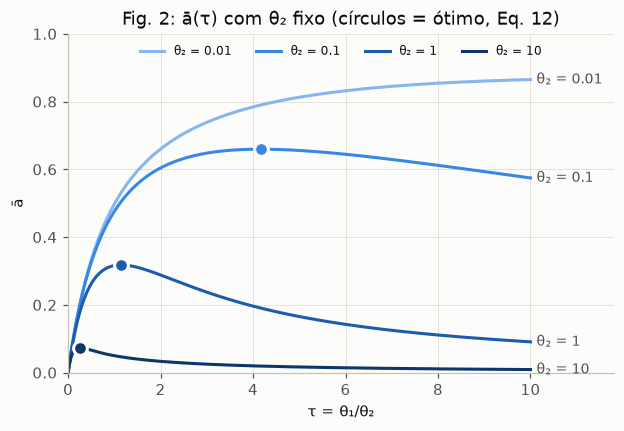

In [7]:
# --- Fig. 2 do artigo ---
tau_v = np.linspace(1e-4, 10, 600)
fig, ax = plt.subplots(figsize=(6.4, 4))
for th2_, cor in zip([0.01, 0.1, 1, 10], RAMPA):
    ax.plot(tau_v, abar_m1(tau_v, th2_), color=cor, label=f'θ₂ = {th2_:g}')
    t1o = theta1_opt_m1(th2_)
    if t1o/th2_ <= 10:
        marca_otimo(ax, t1o/th2_, np.exp(-t1o), cor)
    rotulo(ax, 10, abar_m1(10, th2_), f'θ₂ = {th2_:g}')
ax.set(xlim=(0, 11.8), ylim=(0, 1), xlabel='τ = θ₁/θ₂', ylabel='ā',
       title='Fig. 2: ā(τ) com θ₂ fixo (círculos = ótimo, Eq. 12)')
ax.legend(loc='upper center', ncol=4, fontsize=8)
plt.show()

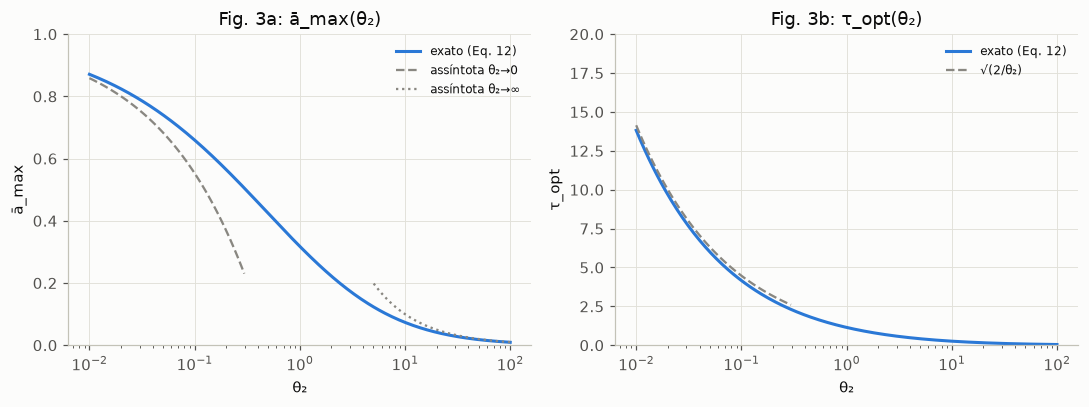

In [8]:
# --- Fig. 3 do artigo (em dois painéis: cada grandeza no seu próprio eixo) ---
th2_v = np.logspace(-2, 2, 300)
t1o_v = theta1_opt_m1(th2_v)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 3.8))
a1.semilogx(th2_v, np.exp(-t1o_v), color=CORES[0], label='exato (Eq. 12)')
a1.semilogx(th2_v[th2_v < 0.3], 1 - np.sqrt(2*th2_v[th2_v < 0.3]), '--', color=MUDO, lw=1.5, label='assíntota θ₂→0')
a1.semilogx(th2_v[th2_v > 5], 1/th2_v[th2_v > 5], ':', color=MUDO, lw=1.5, label='assíntota θ₂→∞')
a1.set(xlabel='θ₂', ylabel='ā_max', ylim=(0, 1), title='Fig. 3a: ā_max(θ₂)'); a1.legend(fontsize=8)
a2.semilogx(th2_v, t1o_v/th2_v, color=CORES[0], label='exato (Eq. 12)')
a2.semilogx(th2_v[th2_v < 0.3], np.sqrt(2/th2_v[th2_v < 0.3]), '--', color=MUDO, lw=1.5, label='√(2/θ₂)')
a2.set(xlabel='θ₂', ylabel='τ_opt', ylim=(0, 20), title='Fig. 3b: τ_opt(θ₂)'); a2.legend(fontsize=8)
plt.tight_layout(); plt.show()

## A.2 Modelo 2: tempo de dessorção variável (Seção 3)

Agora duas misturas gasosas agem sobre o mesmo sólido: uma na adsorção ($C_{Aga}>C_A$) e outra na dessorção ($C_{Agd}<C_A$).
Henry nas duas etapas (Eq. 13): $C_{Asa}=K_{Aa}C_{Aga}$ e $C_{Asd}=K_{Ad}C_{Agd}$.

* **PSA** (varia a pressão): $K_{Aa}=K_{Ad}$, e $C_{Ag}$ muda via $P$ na Eq. 4.
* **TSA** (varia a temperatura): van't Hoff (Eq. 14), $K=K_0\exp(-\Delta U/RT)$.
  **Sinal:** para a adsorção usual (exotérmica), $K$ diminui quando $T$ sobe, então $\Delta U<0$ nessa forma.

**Passo não mostrado no artigo:** com a variável normalizada da Eq. 17,
$$a=\frac{C_A-K_{Ad}C_{Agd}}{K_{Aa}C_{Aga}-K_{Ad}C_{Agd}},$$
a Eq. 1 vira $\dfrac{da}{d\theta}=1-a$ na adsorção e $\dfrac{da}{d\theta}=-a$ na dessorção. Integrando, obtemos as Eqs. 15 e 16.

In [9]:
KAa, KAd, CAga, CAgd = sp.symbols('K_Aa K_Ad C_Aga C_Agd', positive=True)
a0, af = sp.symbols('a_0 a_f', positive=True)
af_ = sp.Function('a')
CA_de_a = KAd*CAgd + af_(theta)*(KAa*CAga - KAd*CAgd)            # inversa da Eq. (17)

# Eq. (1) em θ:  dC_A/dθ = C_As - C_A, com C_As = C_Asa (adsorção) ou C_Asd (dessorção)
ode_ads = sp.Eq(sp.diff(CA_de_a, theta), KAa*CAga - CA_de_a)
ode_des = sp.Eq(sp.diff(CA_de_a, theta), KAd*CAgd - CA_de_a)
print('adsorção:   da/dθ =', sp.simplify(sp.solve(ode_ads, af_(theta).diff(theta))[0]))
print('dessorção:  da/dθ =', sp.simplify(sp.solve(ode_des, af_(theta).diff(theta))[0]))

s15 = sp.dsolve(sp.Eq(af_(theta).diff(theta), 1 - af_(theta)), ics={af_(0): a0})
s16 = sp.dsolve(sp.Eq(af_(theta).diff(theta), -af_(theta)), ics={af_(0): af})
display(Markdown('Eq. (15), adsorção partindo de $a_0$:'), s15)
display(Markdown('Eq. (16), dessorção partindo de $a_f$:'), s16)

adsorção:   da/dθ = 1 - a(theta)
dessorção:  da/dθ = -a(theta)


Eq. (15), adsorção partindo de $a_0$:

Eq. (16), dessorção partindo de $a_f$:

### Fechando o ciclo: Eqs. 18, 19 e 21

Num ciclo periódico, a adsorção leva $a_0\to a_f$ em $\theta_1$ e a dessorção leva $a_f\to a_0$ em $\theta_2$:
$$a_f = 1-(1-a_0)e^{-\theta_1},\qquad a_0=a_f\,e^{-\theta_2}.$$
Eliminando $a_f$ chega-se à Eq. 18. Derivando $\bar a$ (Eq. 19) em relação a $a_0$ chega-se à Eq. 21.
Abaixo o SymPy faz as duas passagens.

Eq. (18):

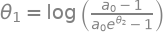

dā/da0 - fator·(Eq.21) = 0


In [10]:
E = sp.exp(th2)
# Eq. (18): eliminar a_f = a0·e^{θ2} da equação da adsorção e isolar θ1
sol18 = sp.solve(sp.Eq(1 - (1 - a0)*sp.exp(-th1), a0*E), th1)
display(Markdown('Eq. (18):'), sp.Eq(th1, sol18[0]))

th1_18 = -sp.log((1 - a0*E)/(1 - a0))
abar2 = a0*(E - 1)/(th1_18 + th2)                                   # Eq. (19)
d_abar2 = sp.diff(abar2, a0)

# Eq. (21) do artigo, escrita como resíduo (LHS - RHS = 0)
res21 = th2 + a0*(1 - E)/((1 - a0)*(1 - a0*E)) - sp.log((1 - a0*E)/(1 - a0))
# Mostramos que dā/da0 = (e^{θ2}-1)/(θ1+θ2)^2 · res21. O fator é > 0, então as raízes coincidem.
diferenca = sp.simplify(d_abar2 - (E - 1)/(th1_18 + th2)**2*res21)
print('dā/da0 - fator·(Eq.21) =', diferenca)

### Resultados extras do modelo 2 (não escritos no artigo)

* **Domínio:** a Eq. 18 exige $a_0e^{\theta_2}<1$, isto é, $0<a_0<e^{-\theta_2}$.
  Por isso a curva $\theta_2=2$ da Fig. 5 termina em $a_0\approx0{,}135$.
* **Parametrização estável:** para $\theta_2$ grande, $a_0$ fica minúsculo (por exemplo $e^{-100}$). É melhor otimizar em
  $a_f\in(0,1)$, com $a_0=a_fe^{-\theta_2}$ e $\theta_1=\ln\dfrac{1-a_0}{1-a_f}$.
* **Valor no ótimo:** substituindo a Eq. 21 na Eq. 19,
  $$\boxed{\bar a_{\max}=(1-a_{0,\mathrm{opt}})(1-a_{f,\mathrm{opt}})}$$
* **Limite $\theta_2\to0$:** por simetria $a_0,a_f\to\tfrac12$, $\tau_{\mathrm{opt}}\to1$ e $\bar a_{\max}\to\tfrac14$ (Fig. 6).

In [11]:
# verificação simbólica de ā_max = (1-a0)(1-af) no ótimo
S = sp.symbols('S', positive=True)                         # S = θ1 + θ2 no ótimo (Eq. 21)
S_otimo = a0*(E - 1)/((1 - a0)*(1 - a0*E))
print('ā_max - (1-a0)(1-af) =', sp.simplify((a0*(E - 1)/S).subs(S, S_otimo) - (1 - a0)*(1 - a0*E)))

ā_max - (1-a0)(1-af) = 0


In [12]:
def estado_m2(af, th2):
    # Ciclo periódico do modelo 2 parametrizado por a_f.
    # Devolve (a0, θ1, ā) pelas Eqs. (16), (18) e (19).
    af = np.asarray(af, dtype=float)
    a0 = af*np.exp(-th2)                          # Eq. (16) em θ = θ2
    th1 = np.log((1 - a0)/(1 - af))               # Eq. (18) reescrita
    abar = (af - a0)/(th1 + th2)                  # Eq. (19)
    return a0, th1, abar

def otimo_m2(th2):
    # Máximo de ā em relação a a0 (ou a_f) para θ2 dado.
    res = minimize_scalar(lambda s: -estado_m2(s, th2)[2], bounds=(1e-12, 1 - 1e-12),
                          method='bounded', options={'xatol': 1e-12})
    af = float(res.x)
    a0, th1, abar = estado_m2(af, th2)
    return dict(theta2=th2, a0=float(a0), af=af, theta1=float(th1),
                tau=float(th1)/th2, abar=float(abar))

def otimo_m2_eq21(th2):
    # Mesmo ótimo, agora resolvendo a Eq. (21) com brentq (validação cruzada).
    def g(af):
        a0 = af*np.exp(-th2)
        th1 = np.log((1 - a0)/(1 - af))
        return th1 + th2 - (af - a0)/((1 - a0)*(1 - af))
    return brentq(g, 1e-12, 1 - 1e-12, xtol=1e-14)

tab = []
for th2_ in [0.01, 0.1, 1, 2, 10, 100]:
    o = otimo_m2(th2_)
    o['af_via_eq21'] = otimo_m2_eq21(th2_)
    o['(1-a0)(1-af)'] = (1 - o['a0'])*(1 - o['af'])
    tab.append(o)
pd.DataFrame(tab)

,theta2,a0,af,theta1,tau,abar,af_via_eq21,(1-a0)(1-af)
0,0.01,4.974959e-01,0.502496,0.010000,0.999983,0.249998,0.502496,0.249998
1,0.10,4.746267e-01,0.524544,0.099834,0.998339,0.249792,0.524544,0.249792
2,1.00,2.534551e-01,0.688963,0.875542,0.875542,0.232203,0.688963,0.232203
3,2.00,1.053508e-01,0.778443,1.395751,0.697876,0.198216,0.778443,0.198216
4,10.00,4.206437e-05,0.926529,2.610827,0.261083,0.073468,0.926529,0.073468
5,100.00,3.684868e-44,0.990536,4.660228,0.046602,0.009464,0.990536,0.009464


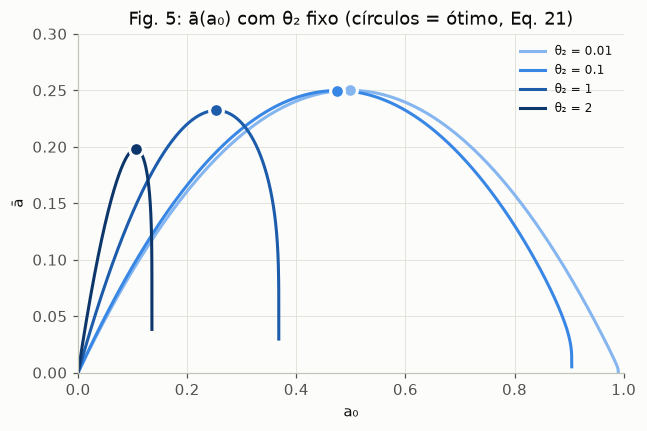

In [13]:
# --- Fig. 5 do artigo ---
fig, ax = plt.subplots(figsize=(6.4, 4))
af_grid = np.linspace(1e-6, 1 - 1e-9, 4000)
for th2_, cor in zip([0.01, 0.1, 1, 2], RAMPA):
    a0g, _, ag = estado_m2(af_grid, th2_)
    ax.plot(a0g, ag, color=cor, label=f'θ₂ = {th2_:g}')
    o = otimo_m2(th2_)
    marca_otimo(ax, o['a0'], o['abar'], cor)
ax.set(xlim=(0, 1), ylim=(0, 0.3), xlabel='a₀', ylabel='ā',
       title='Fig. 5: ā(a₀) com θ₂ fixo (círculos = ótimo, Eq. 21)')
ax.legend(fontsize=8)
plt.show()

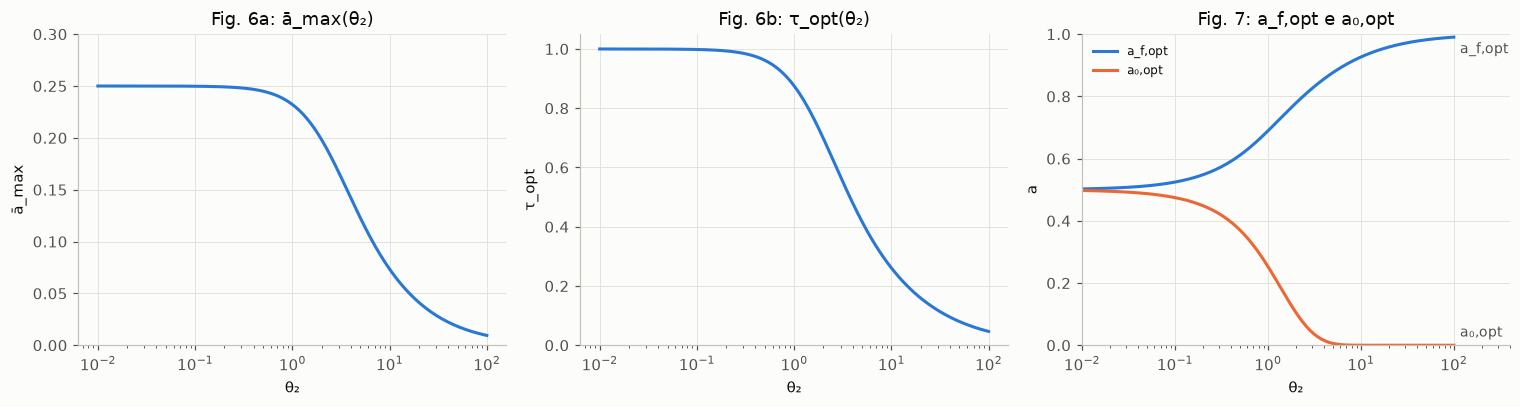

In [14]:
# --- Figs. 6 e 7 do artigo ---
th2_v = np.logspace(-2, 2, 200)
op = pd.DataFrame([otimo_m2(v) for v in th2_v])
fig, (a1, a2, a3) = plt.subplots(1, 3, figsize=(14, 3.8))
a1.semilogx(op.theta2, op.abar, color=CORES[0]); a1.set(xlabel='θ₂', ylabel='ā_max', ylim=(0, 0.3), title='Fig. 6a: ā_max(θ₂)')
a2.semilogx(op.theta2, op.tau, color=CORES[0]); a2.set(xlabel='θ₂', ylabel='τ_opt', ylim=(0, 1.05), title='Fig. 6b: τ_opt(θ₂)')
a3.semilogx(op.theta2, op.af, color=CORES[0], label='a_f,opt')
a3.semilogx(op.theta2, op.a0, color=CORES[1], label='a₀,opt')
rotulo(a3, 100, op.af.iloc[-1], 'a_f,opt', dy=-8); rotulo(a3, 100, op.a0.iloc[-1], 'a₀,opt', dy=8)
a3.set(xlabel='θ₂', ylabel='a', ylim=(0, 1), xlim=(0.01, 400), title='Fig. 7: a_f,opt e a₀,opt'); a3.legend(fontsize=8)
plt.tight_layout(); plt.show()

### Simulação dos ciclos (Fig. 4): do ciclo inicial ao regime periódico

O artigo parametriza o ciclo por $a_0$. Na prática, o operador escolhe **tempos** ($t_1,t_2$), e $a_0$ aparece sozinho
quando o ciclo entra em **regime periódico**. Impondo $a_0=a_f e^{-\theta_2}$ e $a_f=1-(1-a_0)e^{-\theta_1}$:
$$a_0^{*}=\frac{e^{-\theta_2}\,(1-e^{-\theta_1})}{1-e^{-(\theta_1+\theta_2)}}.$$
Abaixo integramos as EDOs numericamente, ciclo a ciclo, partindo de um sólido "limpo" ($a=0$).

θ2 = 1.0:  θ1,opt = 0.8755
a0 pela otimização = 0.253455 | a0* periódico (fórmula) = 0.253455 | a0 após 6 ciclos simulados = 0.253452


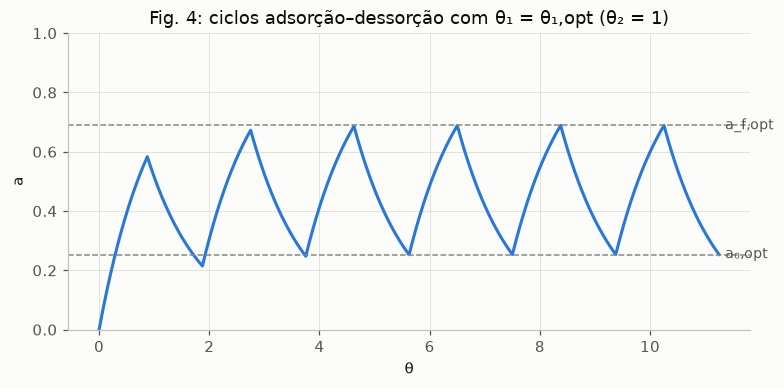

In [15]:
def simula_ciclos_m2(th1, th2, n_ciclos=6, a_ini=0.0, pts=80):
    T, A, a = [], [], a_ini
    t0 = 0.0
    for _ in range(n_ciclos):
        for dur, rhs in [(th1, lambda s, y: 1 - y), (th2, lambda s, y: -y)]:
            s = solve_ivp(rhs, (0, dur), [a], t_eval=np.linspace(0, dur, pts), rtol=1e-10, atol=1e-12)
            T.append(t0 + s.t); A.append(s.y[0]); a = s.y[0][-1]; t0 += dur
    return np.concatenate(T), np.concatenate(A), a

th2_ = 1.0
o = otimo_m2(th2_)
T, A, a_fim = simula_ciclos_m2(o['theta1'], th2_)
a0_star = np.exp(-th2_)*(1 - np.exp(-o['theta1']))/(1 - np.exp(-(o['theta1'] + th2_)))
print(f"θ2 = {th2_}:  θ1,opt = {o['theta1']:.4f}")
print(f"a0 pela otimização = {o['a0']:.6f} | a0* periódico (fórmula) = {a0_star:.6f} | a0 após 6 ciclos simulados = {a_fim:.6f}")

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(T, A, color=CORES[0])
ax.axhline(o['af'], ls='--', color=MUDO, lw=1); rotulo(ax, T[-1], o['af'], 'a_f,opt')
ax.axhline(o['a0'], ls='--', color=MUDO, lw=1); rotulo(ax, T[-1], o['a0'], 'a₀,opt')
ax.set(xlabel='θ', ylabel='a', ylim=(0, 1), title='Fig. 4: ciclos adsorção–dessorção com θ₁ = θ₁,opt (θ₂ = 1)')
plt.show()

## A.3 Modelo 3: concentração variável no gás (Seção 4)

Agora o gás tem volume finito e se empobrece. **Passo não mostrado no artigo (origem da Eq. 22):** por unidade de área de
parede, o que sai do gás (camada de espessura $d$) entra no sólido (espessura $d_s$):
$$d\,\frac{dC_{Ag}}{dt}=-d_s\frac{dC_A}{dt}\ \Rightarrow\ C_{Ag}-C_{Ag0}=-r\,(C_A-C_{A0}),\qquad r=\frac{d_s}{d}\quad\text{(Eqs. 22–23)}$$

Substituindo na Eq. 1 com Henry, $\dfrac{da}{d\theta}=1-(1+rK_A)\,a$, que dá a Eq. 25. No equilíbrio ($C_A=K_AC_{Ag}$) sai a Eq. 24.

In [16]:
r, CAg0 = sp.symbols('r C_Ag0', positive=True)
CAx = sp.symbols('C_A', positive=True)

ode3 = sp.Eq(CA(t).diff(t), Um/ds*(K*(CAg0 - r*(CA(t) - CA0)) - CA(t)))    # Eqs. (1)+(3)+(22)
sol3 = sp.dsolve(ode3, CA(t), ics={CA(0): CA0})
a3 = sp.simplify(((sol3.rhs - CA0)/(K*CAg0 - CA0)).subs(t, theta*ds/Um))    # Eq. (26)
eq25 = (1 - sp.exp(-theta*(1 + r*K)))/(1 + r*K)
print('a(θ) - Eq.(25) =', sp.simplify(a3 - eq25))

CAeq = sp.solve(sp.Eq(CAx, K*(CAg0 - r*(CAx - CA0))), CAx)[0]              # Eq. (24)
display(Markdown('Eq. (24):'), sp.Eq(sp.Symbol('C_{A,eq}'), sp.factor(CAeq)))

a(θ) - Eq.(25) = 0


Eq. (24):

erro máximo = 1.08e-11;  patamar 1/(1+rK) = 0.5000


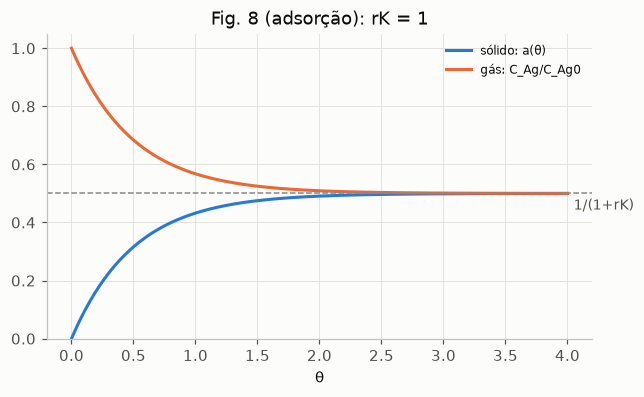

In [17]:
# Verificação numérica: integra C_A e C_Ag acopladas (sem usar a Eq. 22 pronta)
Um_, ds_, K_, CAg0_, CA0_, r_ = 2e-6, 1e-5, 20.0, 0.01, 0.0, 0.05
def rhs(t, y):
    CA_, CAg_ = y
    dCA = Um_/ds_*(K_*CAg_ - CA_)
    return [dCA, -r_*dCA]                        # d·dC_Ag/dt = -d_s·dC_A/dt
tf = 4*ds_/Um_
sn = solve_ivp(rhs, (0, tf), [CA0_, CAg0_], dense_output=True, rtol=1e-10, atol=1e-13)
tt = np.linspace(0, tf, 300); th_ = Um_*tt/ds_
a_num = (sn.sol(tt)[0] - CA0_)/(K_*CAg0_ - CA0_)
a_ana = (1 - np.exp(-th_*(1 + r_*K_)))/(1 + r_*K_)
print(f'erro máximo = {np.abs(a_num - a_ana).max():.2e};  patamar 1/(1+rK) = {1/(1 + r_*K_):.4f}')

fig, ax = plt.subplots(figsize=(6.4, 3.6))
ax.plot(th_, a_num, color=CORES[0], label='sólido: a(θ)')
ax.plot(th_, (sn.sol(tt)[1])/CAg0_, color=CORES[1], label='gás: C_Ag/C_Ag0')
ax.axhline(1/(1 + r_*K_), ls='--', color=MUDO, lw=1); rotulo(ax, th_[-1], 1/(1 + r_*K_), '1/(1+rK)', dy=-8)
ax.set(xlabel='θ', ylim=(0, 1.05), title=f'Fig. 8 (adsorção): rK = {r_*K_:g}'); ax.legend(fontsize=8)
plt.show()

### Taxa média e ótimo (Eqs. 27 e 29): a mudança de variável que "colapsa" o modelo 3 no modelo 1

Com $\beta=1+rK_A$ e $\theta'=\beta\theta$:
$$\bar a=\frac{1-e^{-\beta\theta_1}}{\beta(\theta_1+\theta_2)}=\frac{1-e^{-\theta_1'}}{\theta_1'+\theta_2'}.$$
É **exatamente** a Eq. 7 em variáveis com linha. Logo $\tau_{\mathrm{opt}}(\theta_2,rK)=\tau_{\mathrm{opt}}^{(1)}(\beta\theta_2)$ e
$\bar a_{\max}(\theta_2,rK)=\bar a_{\max}^{(1)}(\beta\theta_2)=e^{-\beta\theta_{1,\mathrm{opt}}}$.
A Fig. 9 do artigo é a Fig. 3 deslocada no eixo $\theta_2$.

θ2=0.05  rK=0.1   θ1 numérico=0.285726  θ1 colapso=0.285726
θ2=1     rK=1     θ1 numérico=0.752621  θ1 colapso=0.752621
θ2=3     rK=10    θ1 numérico=0.329795  θ1 colapso=0.329795


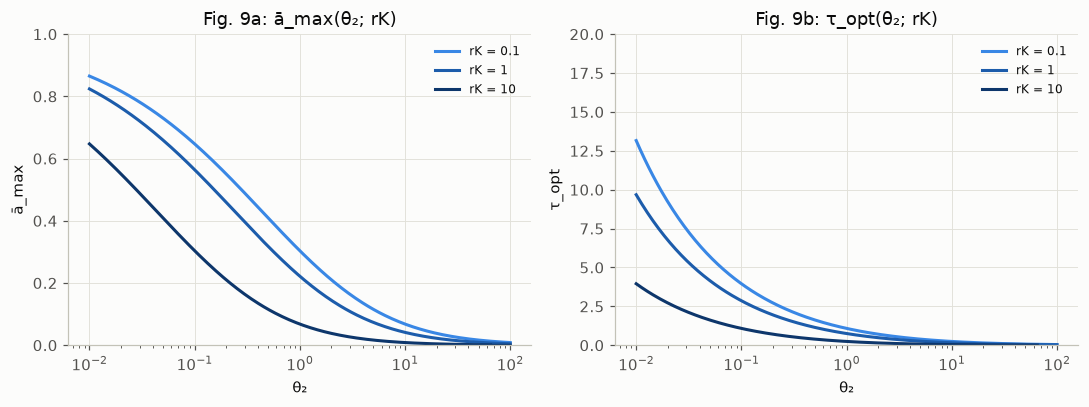

In [18]:
def abar_m3(th1, th2, rK):
    b = 1 + rK
    return (1 - np.exp(-b*th1))/(b*(th1 + th2))             # Eq. (27)

def theta1_opt_m3(th2, rK):
    b = 1 + rK
    return theta1_opt_m1(b*th2)/b                           # colapso: θ1' = β θ1

# validação: maximização numérica direta da Eq. (27) x fórmula do colapso
for th2_, rK_ in [(0.05, 0.1), (1, 1), (3, 10)]:
    num = minimize_scalar(lambda x: -abar_m3(x, th2_, rK_), bounds=(1e-9, 50), method='bounded', options={'xatol': 1e-12}).x
    print(f'θ2={th2_:<5} rK={rK_:<4}  θ1 numérico={num:.6f}  θ1 colapso={theta1_opt_m3(th2_, rK_):.6f}')

# --- Fig. 9 do artigo ---
th2_v = np.logspace(-2, 2, 300)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 3.8))
for rK_, cor in zip([0.1, 1, 10], RAMPA[1:]):
    t1o = theta1_opt_m3(th2_v, rK_)
    a1.semilogx(th2_v, abar_m3(t1o, th2_v, rK_), color=cor, label=f'rK = {rK_:g}')
    a2.semilogx(th2_v, t1o/th2_v, color=cor, label=f'rK = {rK_:g}')
a1.set(xlabel='θ₂', ylabel='ā_max', ylim=(0, 1), title='Fig. 9a: ā_max(θ₂; rK)'); a1.legend(fontsize=8)
a2.set(xlabel='θ₂', ylabel='τ_opt', ylim=(0, 20), title='Fig. 9b: τ_opt(θ₂; rK)'); a2.legend(fontsize=8)
plt.tight_layout(); plt.show()

---
# PARTE B: Estrutura espacial (Seções 5–8)

## B.1 Volume elementar (Seção 5)

O tempo ótimo fixa as escalas de comprimento: o gás e o sólido devem ser **inteiramente** penetrados por difusão
durante $t_1$ e $t_2$ (Eqs. 30–32):
$$d\sim(Dt_1)^{1/2},\qquad d_s\sim(D_st_1)^{1/2}\ \Rightarrow\ t_1\sim t_2\ \text{(Eq. 33)},\qquad \frac{d_s}{d}\sim\Big(\frac{D_s}{D}\Big)^{1/2}\ \text{(Eq. 34)}$$

O canal é usado inteiro quando o gás o percorre no mesmo tempo, $L=Ut_1$ (Eq. 35). Com escoamento laminar desenvolvido,
$U\sim d^2\Delta P/(\mu L)$ (Eq. 36). **Passo omitido:** eliminar $U$ e $t_1=d^2/D$ leva à Eq. 37.

> **Erros de referência no artigo:** o texto diz "Combining Eqs. (29), (35) and (36)" e "Eqs. (37) and (29)".
> O correto é a **Eq. (30)**; a Eq. 29 é a condição de $\tau_{\mathrm{opt}}$ da Seção 4.

Outro passo que o artigo usa sem escrever (e que é necessário nas Seções 6–8) é a **vazão mássica de gás por volume**:
$$\dot m'''=\frac{\rho U d}{L d}=\frac{\rho U}{L}=\frac{\rho}{t_1}\qquad\Big(\text{consistente com } \dot n'''\sim\Delta C\,\frac{U}{L}\ \text{(Eq. 43)}\Big)$$

In [19]:
D, Ds_, t1_, dP, mu, rho, L, U, d, dC = sp.symbols('D D_s t_1 DeltaP mu rho L U d DeltaC', positive=True)

d_expr  = sp.sqrt(D*t1_)                                   # Eq. (30)
ds_expr = sp.sqrt(Ds_*t1_)                                 # Eq. (31)
display(Markdown('Eq. (34):'), sp.Eq(sp.Symbol('d_s/d'), sp.simplify(ds_expr/d_expr)))

solLU = sp.solve([sp.Eq(L, U*t1_), sp.Eq(U, d**2*dP/(mu*L))], [L, U], dict=True)[0]   # Eqs. (35)-(36)
L_expr = solLU[L]
display(Markdown('Eq. (37):'), sp.Eq(sp.Symbol('L/d^2'), sp.simplify((L_expr/d**2).subs(t1_, d**2/D))))

# Eq. (38)-(39): esbeltez L/d > 1
L_d = sp.simplify((L_expr/d).subs(t1_, d**2/D))
d_min = sp.solve(sp.Eq(L_d, 1), d)[0]
display(Markdown('Eq. (38), $d$ mínimo:'), sp.Eq(sp.Symbol('d_min'), d_min))
display(Markdown('Eq. (39), $t_1$ mínimo:'), sp.Eq(sp.Symbol('t_1min'), sp.simplify(d_min**2/D)))

# Eq. (40)-(43): taxa volumétrica de remoção
jA = D*dC/d
ndot_41 = sp.simplify((jA*L_expr*t1_/(L_expr*d*t1_)).subs(d, d_expr))
ndot_43 = sp.simplify(dC*solLU[U]/L_expr)
print('ṅ\'\'\' pela Eq. (41):', ndot_41, '   pela Eq. (43):', ndot_43.subs(d, d_expr))
print('limite da Eq. (42): ṅ\'\'\' < ΔC/t1_min =', sp.simplify(dC/(d_min**2/D)))
print('m\'\'\' = ρU/L =', sp.simplify(rho*solLU[U]/L_expr))

Eq. (34):

Eq. (37):

Eq. (38), $d$ mínimo:

Eq. (39), $t_1$ mínimo:

ṅ''' pela Eq. (41): DeltaC/t_1    pela Eq. (43): DeltaC/t_1
limite da Eq. (42): ṅ''' < ΔC/t1_min = DeltaC*DeltaP/mu
m''' = ρU/L = rho/t_1


## B.2 Construtos 1, 2, 3, … : derivação simbólica **genérica** (Seções 6–8)

O artigo mostra as contas do 1º construto e só os resultados do 2º e do 3º. O padrão geométrico é recursivo
e pode ser escrito para um nível $i$ qualquer. Aqui o elemento é tratado como "construto 0":

| | construto 0 (elemento) | construto $i\ge1$ |
|---|---|---|
| área | $A_0=Ld$ | $A_i=n_iA_{i-1}=L_{i-1}L_i$ |
| lados | $L_{-1}=d$, $L_0=L$ | $L_i=n_i\,L_{i-2}$ |
| canal coletor | — | espessura $d_i=\phi_iL_{i-1}$, comprimento $L_i$ |
| vazão | $\dot m'_0=\dot m'_1/n_1$ | $\dot m'_i=\dot m'''A_i$ |

Em cada canal vale Hagen–Poiseuille em escala: $\Delta P\sim\nu\,\dot m' L/d_{\text{canal}}^3$. Então
$$\Delta P_i=\underbrace{\Delta P_{i-1}\!\Big(\tfrac{\dot m'_i}{n_i},\tfrac{A_i}{n_i}\Big)}_{\text{interno}}+\underbrace{\nu\,\dot m'_i\,\frac{L_i}{(\phi_iL_{i-1})^3}}_{\text{canal do nível }i}.$$

Em forma adimensional, com $x=A/d^2$ e $\Delta P_i=\dfrac{\nu\dot m'_i}{d^2}\,\Pi_i(x)$, $\Pi_0(x)=x$ e $R_i=L_i/L_{i-1}$ ($R_0=x$):
$$\Pi_i(x;n)=\frac{\Pi_{i-1}(x/n)}{n}+\frac{n}{\phi_i^3\,(x/n)\,R_{i-1}(x/n)^2}.$$

O artigo escolhe $n$ igualando os dois termos (regra de escala: "mesma ordem de grandeza"). Todas as grandezas são
**monômios**, então a equação $\text{termo}_1=\text{termo}_2$ é linear nos logaritmos e tem solução exata.
A potência de bombeamento é $\dot W'_i=\dot m'_i\Delta P_i/\rho=(\dot m''')^2\nu d^2x^2\,\Pi_i/\rho$.

In [20]:
x, n = sp.symbols('x n', positive=True)           # x = A/d²
NMAX = 5                                           # vamos até o 5º construto
phi = sp.symbols(f'phi1:{NMAX + 1}', positive=True)
Rat = sp.Rational

def simp(e):
    return sp.powsimp(sp.expand_power_base(sp.powdenest(e, force=True), force=True), force=True)

def resolve_monomio(t1, t2, var):
    # Resolve t1 = t2 para var, quando t1/t2 é um monômio C·var^a·(resto).
    a, resto = 0, sp.Integer(1)
    for f in sp.Mul.make_args(simp(t1/t2)):
        b, e = f.as_base_exp()
        if b == var: a += e
        else: resto *= f
    return simp(resto**(-sp.Integer(1)/a))

construto = {0: dict(Pi=x, R=x)}
for i in range(1, NMAX + 1):
    Pm, Rm = construto[i-1]['Pi'], construto[i-1]['R']
    xm = x/n
    t_int = simp(Pm.subs(x, xm)/n)                          # termo interno
    t_can = simp(n/(phi[i-1]**3*xm*Rm.subs(x, xm)**2))      # termo do canal de nível i
    n_opt = resolve_monomio(t_int, t_can, n)                # termos de mesma ordem
    construto[i] = dict(t_int=t_int, t_can=t_can, n=n_opt,
                        Pi=simp(t_int.subs(n, n_opt)),
                        R=simp((n/Rm.subs(x, xm)).subs(n, n_opt)))
    construto[i]['W'] = simp(x**2*construto[i]['Pi'])       # Ẇ' / [(ṁ''')² ν d²/ρ]

for i in range(1, NMAX + 1):
    c = construto[i]
    display(Markdown(f'**Construto {i}**: $n_{{{i},opt}} = {sp.latex(c["n"])}$, '
                     f'$L_{i}/L_{{{i-1}}} = {sp.latex(c["R"])}$, '
                     f'$\\Delta P_{i} d^2/(\\nu \\dot m\'_{i}) = {sp.latex(c["Pi"])}$, '
                     f'$\\dot W\'_{i} \\propto {sp.latex(c["W"])}$'))

**Construto 1**: $n_{1,opt} = \sqrt{\phi_{1}} x^{\frac{2}{3}}$, $L_1/L_{0} = \phi_{1} \sqrt[3]{x}$, $\Delta P_1 d^2/(\nu \dot m'_1) = \frac{1}{\phi_{1} \sqrt[3]{x}}$, $\dot W'_1 \propto \frac{x^{\frac{5}{3}}}{\phi_{1}}$

**Construto 2**: $n_{2,opt} = \phi_{1}^{\frac{3}{10}} \phi_{2}^{\frac{9}{10}} x^{\frac{2}{5}}$, $L_2/L_{1} = \frac{\phi_{2}^{\frac{6}{5}} \sqrt[5]{x}}{\phi_{1}^{\frac{3}{5}}}$, $\Delta P_2 d^2/(\nu \dot m'_2) = \frac{1}{\phi_{1}^{\frac{6}{5}} \phi_{2}^{\frac{3}{5}} x^{\frac{3}{5}}}$, $\dot W'_2 \propto \frac{x^{\frac{7}{5}}}{\phi_{1}^{\frac{6}{5}} \phi_{2}^{\frac{3}{5}}}$

**Construto 3**: $n_{3,opt} = \frac{\phi_{2}^{\frac{9}{14}} \phi_{3}^{\frac{15}{14}} x^{\frac{2}{7}}}{\phi_{1}^{\frac{6}{7}}}$, $L_3/L_{2} = \frac{\phi_{3}^{\frac{9}{7}} \sqrt[7]{x}}{\phi_{1}^{\frac{3}{7}} \phi_{2}^{\frac{3}{7}}}$, $\Delta P_3 d^2/(\nu \dot m'_3) = \frac{1}{\phi_{1}^{\frac{6}{7}} \phi_{2}^{\frac{6}{7}} \phi_{3}^{\frac{3}{7}} x^{\frac{5}{7}}}$, $\dot W'_3 \propto \frac{x^{\frac{9}{7}}}{\phi_{1}^{\frac{6}{7}} \phi_{2}^{\frac{6}{7}} \phi_{3}^{\frac{3}{7}}}$

**Construto 4**: $n_{4,opt} = \frac{\phi_{3}^{\frac{5}{6}} \phi_{4}^{\frac{7}{6}} x^{\frac{2}{9}}}{\phi_{1}^{\frac{2}{3}} \phi_{2}^{\frac{2}{3}}}$, $L_4/L_{3} = \frac{\phi_{4}^{\frac{4}{3}} \sqrt[9]{x}}{\sqrt[3]{\phi_{1}} \sqrt[3]{\phi_{2}} \sqrt[3]{\phi_{3}}}$, $\Delta P_4 d^2/(\nu \dot m'_4) = \frac{1}{\phi_{1}^{\frac{2}{3}} \phi_{2}^{\frac{2}{3}} \phi_{3}^{\frac{2}{3}} \sqrt[3]{\phi_{4}} x^{\frac{7}{9}}}$, $\dot W'_4 \propto \frac{x^{\frac{11}{9}}}{\phi_{1}^{\frac{2}{3}} \phi_{2}^{\frac{2}{3}} \phi_{3}^{\frac{2}{3}} \sqrt[3]{\phi_{4}}}$

**Construto 5**: $n_{5,opt} = \frac{\phi_{4}^{\frac{21}{22}} \phi_{5}^{\frac{27}{22}} x^{\frac{2}{11}}}{\phi_{1}^{\frac{6}{11}} \phi_{2}^{\frac{6}{11}} \phi_{3}^{\frac{6}{11}}}$, $L_5/L_{4} = \frac{\phi_{5}^{\frac{15}{11}} \sqrt[11]{x}}{\phi_{1}^{\frac{3}{11}} \phi_{2}^{\frac{3}{11}} \phi_{3}^{\frac{3}{11}} \phi_{4}^{\frac{3}{11}}}$, $\Delta P_5 d^2/(\nu \dot m'_5) = \frac{1}{\phi_{1}^{\frac{6}{11}} \phi_{2}^{\frac{6}{11}} \phi_{3}^{\frac{6}{11}} \phi_{4}^{\frac{6}{11}} \phi_{5}^{\frac{3}{11}} x^{\frac{9}{11}}}$, $\dot W'_5 \propto \frac{x^{\frac{13}{11}}}{\phi_{1}^{\frac{6}{11}} \phi_{2}^{\frac{6}{11}} \phi_{3}^{\frac{6}{11}} \phi_{4}^{\frac{6}{11}} \phi_{5}^{\frac{3}{11}}}$

In [21]:
# --- Conferência: os colchetes das Eqs. (48) e (55) são reproduzidos pela recursão ---
p1, p2, p3 = phi[:3]
n1, n2 = sp.symbols('n1 n2', positive=True)
eq48 = x/n1**2 + n1**4/(p1**3*x**3)                         # Eq. (48) ÷ (ν ṁ'/d²)
rec1 = (construto[1]['t_int'] + construto[1]['t_can']).subs(n, n1)
print('Eq. (48) - recursão =', sp.simplify(eq48 - rec1))

eq55 = n2**Rat(8,3)/(p1**2*p2**3)*x**Rat(-5,3) + x**Rat(-1,3)/(n2**Rat(2,3)*p1)   # Eq. (55), 2ª forma
rec2 = (construto[2]['t_int'] + construto[2]['t_can']).subs(n, n2)
print('Eq. (55) - recursão =', sp.simplify(eq55 - rec2))

# L/d do elemento no ótimo (Eq. 50): L/d = x/n1
print('Eq. (50): L/d =', simp(x/construto[1]['n']))

Eq. (48) - recursão = 0
Eq. (55) - recursão = 0
Eq. (50): L/d = x**(1/3)/sqrt(phi1)


In [22]:
# --- Comparação automática com as fórmulas IMPRESSAS no artigo ---
publicado = {
  (1, 'n'):  (49, p1**Rat(1,2)*x**Rat(2,3)),
  (1, 'R'):  (51, p1*x**Rat(1,3)),
  (1, 'Pi'): (52, x**Rat(-1,3)/p1),
  (1, 'W'):  (53, x**Rat(5,3)/p1),
  (2, 'n'):  (56, p1**Rat(3,10)*p2**Rat(9,10)*x**Rat(2,5)),
  (2, 'R'):  (57, p1**Rat(-3,5)*p2**Rat(6,5)*x**Rat(1,5)),
  (2, 'Pi'): (58, x**Rat(-3,5)/(p1**Rat(6,5)*p2**Rat(3,5))),
  (2, 'W'):  (59, x**Rat(7,5)/(p1**Rat(6,5)*p2**Rat(3,5))),
  (3, 'n'):  (61, p1**Rat(-9,14)*p2**Rat(9,14)*p3**Rat(15,14)*x**Rat(2,7)),
  (3, 'R'):  (62, p1**Rat(-3,7)*p2**Rat(-3,7)*p3**Rat(9,7)*x**Rat(1,7)),
  (3, 'Pi'): (63, x**Rat(-5,7)/(p1**Rat(6,7)*p2**Rat(6,7)*p3**Rat(3,7))),
  (3, 'W'):  (64, x**Rat(9,7)/(p1**Rat(6,7)*p2**Rat(6,7)*p3**Rat(3,7))),
}
linhas = []
for (i, k), (eqn, pub) in publicado.items():
    der = construto[i][k]
    razao = simp(der/pub)
    linhas.append({'Eq.': eqn, 'grandeza': f'{k} (construto {i})', 'derivado': str(der),
                   'publicado': str(pub), 'confere?': 'OK' if razao == 1 else f'DIFERENTE (derivado/publicado = {razao})'})
pd.set_option('display.max_colwidth', 120)
pd.DataFrame(linhas)

,Eq.,grandeza,derivado,publicado,confere?
0,49,n (construto 1),sqrt(phi1)*x**(2/3),sqrt(phi1)*x**(2/3),OK
1,51,R (construto 1),phi1*x**(1/3),phi1*x**(1/3),OK
2,52,Pi (construto 1),1/(phi1*x**(1/3)),1/(phi1*x**(1/3)),OK
3,53,W (construto 1),x**(5/3)/phi1,x**(5/3)/phi1,OK
4,56,n (construto 2),phi1**(3/10)*phi2**(9/10)*x**(2/5),phi1**(3/10)*phi2**(9/10)*x**(2/5),OK
5,57,R (construto 2),phi2**(6/5)*x**(1/5)/phi1**(3/5),phi2**(6/5)*x**(1/5)/phi1**(3/5),OK
6,58,Pi (construto 2),1/(phi1**(6/5)*phi2**(3/5)*x**(3/5)),1/(phi1**(6/5)*phi2**(3/5)*x**(3/5)),OK
7,59,W (construto 2),x**(7/5)/(phi1**(6/5)*phi2**(3/5)),x**(7/5)/(phi1**(6/5)*phi2**(3/5)),OK
8,61,n (construto 3),phi2**(9/14)*phi3**(15/14)*x**(2/7)/phi1**(6/7),phi2**(9/14)*phi3**(15/14)*x**(2/7)/phi1**(9/14),DIFERENTE (derivado/publicado = phi1**(-3/14))
9,62,R (construto 3),phi3**(9/7)*x**(1/7)/(phi1**(3/7)*phi2**(3/7)),phi3**(9/7)*x**(1/7)/(phi1**(3/7)*phi2**(3/7)),OK


**Resultado:** tudo confere, **exceto a Eq. 61**. O expoente correto de $\phi_1$ em $n_{3,\mathrm{opt}}$ é $-6/7=-12/14$, e não $-9/14$.
Três verificações sustentam a correção: (i) as Eqs. 62, 63 e 64, que dependem de $n_{3,\mathrm{opt}}$, só conferem com $-6/7$;
(ii) a recursão acima; (iii) a igualdade dos dois termos pode ser checada à mão.

### Tamanhos de transição (Eqs. 60 e 65) e sequências de expoentes (Eq. 69)

In [23]:
A12 = resolve_monomio(construto[1]['W'], construto[2]['W'], x)
A23 = resolve_monomio(construto[2]['W'], construto[3]['W'], x)
print('A_{1-2}/d² =', A12, '   | Eq. (60) publicada: phi1**(-3/4)*phi2**(-9/4)  ->',
      'OK' if simp(A12/(p1**Rat(-3,4)*p2**Rat(-9,4))) == 1 else 'DIFERENTE')
print('A_{2-3}/d² =', A23, '   | Eq. (65) publicada: phi1**3*phi2**(-9/4)*phi3**(-15/4)  ->',
      'OK' if simp(A23/(p1**3*p2**Rat(-9,4)*p3**Rat(-15,4))) == 1 else 'DIFERENTE')

f = sp.symbols('phi', positive=True)
tab = []
for i in range(1, NMAX + 1):
    todos_iguais = {phi[j]: f for j in range(NMAX)}
    Ri = simp(construto[i]['R'].subs(todos_iguais))
    Wi = simp(construto[i]['W'].subs(todos_iguais))
    ex = lambda e, s: sp.Poly(sp.expand_log(sp.log(e), force=True).subs(sp.log(s), sp.Symbol('LOG')).subs(
        {sp.log(v): 0 for v in (x, f) if v != s}), sp.Symbol('LOG')).coeffs()[0]
    tab.append(dict(construto=i,
                    m_expoente_W_vs_A=ex(Wi, x),
                    q_expoente_razao_aspecto=ex(Ri, x),
                    p_expoente_phi_razao_aspecto=ex(Ri, f),
                    transicao_para_o_seguinte=(str(simp(resolve_monomio(construto[i]['W'], construto[i+1]['W'], x).subs(todos_iguais)))
                                               if i < NMAX else '')))
pd.DataFrame(tab)

A_{1-2}/d² = 1/(phi1**(3/4)*phi2**(9/4))    | Eq. (60) publicada: phi1**(-3/4)*phi2**(-9/4)  -> OK
A_{2-3}/d² = phi1**3/(phi2**(9/4)*phi3**(15/4))    | Eq. (65) publicada: phi1**3*phi2**(-9/4)*phi3**(-15/4)  -> OK


,construto,m_expoente_W_vs_A,q_expoente_razao_aspecto,p_expoente_phi_razao_aspecto,transicao_para_o_seguinte
0,1,5/3,1/3,1,phi**(-3)
1,2,7/5,1/5,3/5,phi**(-3)
2,3,9/7,1/7,3/7,phi**(-3)
3,4,11/9,1/9,1/3,phi**(-3)
4,5,13/11,1/11,3/11,


**Leitura da tabela:**
* $m=5/3,\,7/5,\,9/7,\,11/9,\,13/11$, ou seja $m=(2i+3)/(2i+1)\to1$. Isso **confirma** a extrapolação "por inspeção" do artigo.
* $q=1/3,\,1/5,\,1/7,\dots=1/(2i+1)$, como no artigo.
* $p=1,\,3/5,\,3/7,\,1/3,\,3/11=3/(2i+1)$. O artigo imprime **$p=9/35$** para $i=3$, mas a própria Eq. 62 com
  $\phi_1=\phi_2=\phi_3=\phi$ dá $\phi^{-3/7-3/7+9/7}=\phi^{3/7}=\phi^{15/35}$. É erro tipográfico.
* **Observação que o artigo não faz:** com todos os $\phi$ iguais, **todas** as curvas $\dot W'_i(A)$ se cruzam no mesmo ponto,
  $A/d^2=\phi^{-3}$. Abaixo dele o construto mais simples é o melhor; acima, o mais complexo. Na prática isso vale
  enquanto $n_i\ge2$ em todos os níveis (a Parte C verifica).

## B.3 Distribuição ótima das frações de volume dos canais (Seção 8, Eqs. 66–68)

O volume total de canais é fixo. Estendendo a Eq. 66 para qualquer nível: $\phi_{1k}=\phi_{1,k-1}+2\phi_k$, isto é
$$\sum_j c_j\phi_j=\Phi,\qquad c_1=1,\ c_{j\ge2}=2\ \text{(duas árvores, entrada e saída, "copa com copa")}.$$

Como $\dot W'_k\propto\prod_j\phi_j^{-e_j}$, o problema é maximizar $\sum_j e_j\ln\phi_j$ sujeito a $\sum_jc_j\phi_j=\Phi$.
Com multiplicadores de Lagrange (passo não mostrado no artigo) sai uma **fórmula fechada geral**:
$$\boxed{\phi_j=\frac{e_j}{c_j\sum_i e_i}\,\Phi}$$

> **Inconsistências no texto do artigo:**
> * Para $k=2$ ($e=(6/5,3/5)$), a fórmula dá $\phi_1=\tfrac23\phi_{12}$ ✔ e **$\phi_2=\tfrac16\phi_{12}$**. O artigo imprime
>   $\phi_2=\phi_{12}/4$, o que viola a própria restrição (Eq. 67): $2\cdot\tfrac14+\tfrac23=\tfrac76\ne1$.
> * Para $k=3$ o artigo otimiza **em sequência** (primeiro $\phi_1{:}\phi_2$ pelo critério do 2º construto, depois $\phi_{12}{:}\phi_3$).
>   Isso dá $\phi_3=\Phi/10$ ✔ e $\phi_{12}=4\Phi/5$ ✔, mas $\phi_1=\tfrac{8}{15}\Phi$ e $\phi_2=\tfrac{2}{15}\Phi$ (o artigo imprime $\tfrac15\Phi$;
>   com esse valor a soma dá $17/15$). O **ótimo global** de $\dot W'_3$ é $\phi_1=\tfrac25\Phi$, $\phi_2=\tfrac15\Phi$, $\phi_3=\tfrac1{10}\Phi$,
>   cerca de 10% menos potência que o ótimo sequencial.
> * A Eq. 66 conta **um** canal $d_1$ por 1º construto ($c_1=1$), mas a Fig. 11 desenha dois (entrada e saída).
>   Na Parte C isso é ajustável em `CANAIS_POR_NIVEL`.

In [24]:
def expoentes_phi(k):
    # e_j tais que Ẇ'_k ∝ Π φ_j^(-e_j)
    W = construto[k]['W']
    return [-sp.Poly(sp.expand_log(sp.log(W), force=True).subs(sp.log(phi[j]), sp.Symbol('LG')).subs(
        {sp.log(v): 0 for v in list(phi[:NMAX]) + [x] if v != phi[j]}), sp.Symbol('LG')).coeffs()[0]
        for j in range(k)]

def phi_otimos(k, Phi=1, c=None):
    # Fórmula fechada de Lagrange: φ_j = e_j Φ / (c_j Σe)
    e = expoentes_phi(k)
    c = c or [1] + [2]*(k - 1)
    return [ej*Phi/(cj*sum(e)) for ej, cj in zip(e, c)]

# 1) Lagrange simbólico explícito para k = 2 e k = 3
Phi_, lam = sp.symbols('Phi lambda', positive=True)
for k in (2, 3):
    e = expoentes_phi(k); c = [1] + [2]*(k - 1)
    Lg = sum(ej*sp.log(phi[j]) for j, ej in enumerate(e)) - lam*(sum(cj*phi[j] for j, cj in enumerate(c)) - Phi_)
    sol = sp.solve([sp.diff(Lg, v) for v in phi[:k]] + [sp.diff(Lg, lam)], list(phi[:k]) + [lam], dict=True)[0]
    print(f'k={k}: expoentes e = {e} ->', {str(v): sp.simplify(sol[v]) for v in phi[:k]})

# 2) Checagem numérica (SLSQP) para k = 3 e comparação dos cenários
k = 3; Wfun = sp.lambdify(phi[:3], construto[3]['W'].subs(x, 1))
cons = {'type': 'eq', 'fun': lambda p: p[0] + 2*p[1] + 2*p[2] - 1}
num = minimize(lambda p: np.log(Wfun(*p)), [0.3, 0.2, 0.1], constraints=[cons],
               bounds=[(1e-6, 1)]*3, method='SLSQP', options={'ftol': 1e-14})
cen = {
    'ótimo global (Lagrange)':      [float(v) for v in phi_otimos(3)],
    'ótimo global (SLSQP)':         list(num.x),
    'sequencial, corrigido':        [8/15, 2/15, 1/10],
    'como impresso no artigo':      [8/15, 1/5, 1/10],
}
pd.DataFrame([dict(cenário=n_, phi1=p[0], phi2=p[1], phi3=p[2],
                   soma_phi1_2phi2_2phi3=p[0] + 2*p[1] + 2*p[2],
                   W_relativo_ao_global=Wfun(*p)/Wfun(*cen['ótimo global (Lagrange)']))
              for n_, p in cen.items()])

k=2: expoentes e = [6/5, 3/5] -> {'phi1': 2*Phi/3, 'phi2': Phi/6}


k=3: expoentes e = [6/7, 6/7, 3/7] -> {'phi1': 2*Phi/5, 'phi2': Phi/5, 'phi3': Phi/10}


,cenário,phi1,phi2,phi3,soma_phi1_2phi2_2phi3,W_relativo_ao_global
0,ótimo global (Lagrange),0.400000,0.200000,0.1,1.000000,1.000000
1,ótimo global (SLSQP),0.400000,0.200000,0.1,1.000000,1.000000
2,"sequencial, corrigido",0.533333,0.133333,0.1,1.000000,1.106229
3,como impresso no artigo,0.533333,0.200000,0.1,1.133333,0.781465


## B.4 Constantes de ordem 1 e robustez

A regra "termos iguais" é uma aproximação de escala. O mínimo exato de $\Pi_i(n)$ fica um pouco deslocado, e a curva
é **achatada** perto do ótimo. Esse achatamento é a robustez que o artigo menciona nas conclusões: afastar-se do ótimo custa pouco.

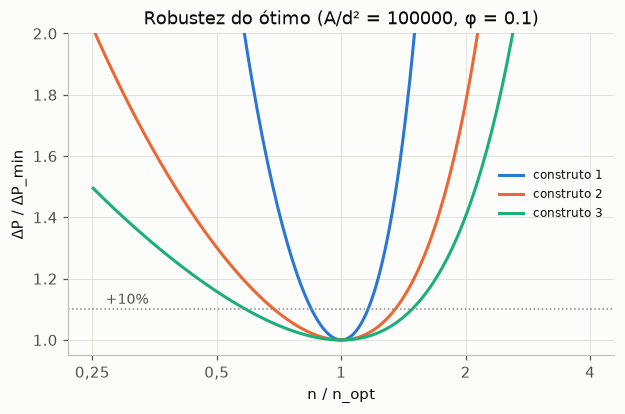

,construto,n_escala,n_exato,razao_n,Pi_escala_1termo,Pi_min_exato,razao_Pi
0,1,681.292069,606.962208,0.890899,0.215443,0.407163,1.889882
1,2,6.309573,4.162767,0.659754,0.063096,0.104069,1.649385
2,3,3.727594,1.965700,0.527337,0.037276,0.056175,1.506993


In [25]:
xv, fv = 1e5, 0.1                          # A/d² e φ (todos iguais), só para ilustrar
subs_phi = {phi[j]: fv for j in range(NMAX)}
fig, ax = plt.subplots(figsize=(6.4, 3.8))
tab = []
for i, cor in zip([1, 2, 3], CORES):
    c = construto[i]
    tot = sp.lambdify(n, (c['t_int'] + c['t_can']).subs(subs_phi).subs(x, xv))
    n_esc = float(c['n'].subs(subs_phi).subs(x, xv))
    r_ = minimize_scalar(lambda ln_: tot(np.exp(ln_)), bounds=(np.log(n_esc) - 3, np.log(n_esc) + 3), method='bounded')
    n_ex, Pmin = np.exp(r_.x), r_.fun
    tab.append(dict(construto=i, n_escala=n_esc, n_exato=n_ex, razao_n=n_ex/n_esc,
                    Pi_escala_1termo=float(c['Pi'].subs(subs_phi).subs(x, xv)), Pi_min_exato=Pmin,
                    razao_Pi=Pmin/float(c['Pi'].subs(subs_phi).subs(x, xv))))
    rr = np.logspace(-0.6, 0.6, 200)
    ax.semilogx(rr, [tot(n_ex*v)/Pmin for v in rr], color=cor, label=f'construto {i}')
ax.axhline(1.1, ls=':', color=MUDO, lw=1); rotulo(ax, 0.26, 1.1, '+10%', dy=6)
ax.set_xticks([0.25, 0.5, 1, 2, 4]); ax.set_xticklabels(['0,25', '0,5', '1', '2', '4']); ax.minorticks_off()
ax.set(xlabel='n / n_opt', ylabel='ΔP / ΔP_min', ylim=(0.95, 2), title=f'Robustez do ótimo (A/d² = {xv:g}, φ = {fv})')
ax.legend(fontsize=8); plt.show()
pd.DataFrame(tab)

Com a regra de escala, $n$ fica dentro de ~10% do ótimo exato, e $\Delta P$ real no ótimo é ~1,5–2× o "termo único".
Esses fatores mudam os valores absolutos, mas **não** mudam as leis de potência nem as comparações entre construtos.

---
# PARTE C: Pipeline com valores reais

## C.0 PARÂMETROS DO USUÁRIO: **substitua aqui**

Os valores abaixo são **ilustrativos** (CO₂/N₂ num adsorvente genérico em camada fina, operação PSA) e servem só para o
notebook rodar do começo ao fim. Troque pelos seus e rode *Ambiente de execução → Executar tudo*.
Onde há `None`, o notebook estima o valor por uma correlação (documentada na Parte D).

In [26]:
# ======================================================================
#  PARÂMETROS DO USUÁRIO: SUBSTITUA PELOS SEUS VALORES REAIS
# ======================================================================
R_GAS = 8314.462618        # J/(kmol·K)

# ---- Modelo temporal: 1 = Seção 2 | 2 = Seção 3 | 3 = Seção 4
MODELO = 2

# ---- Etapa de ADSORÇÃO (gás de alimentação)
P_ADS   = 1.5e5            # Pa     pressão total
T_ADS   = 298.15           # K
Y_A_ADS = 0.15             # -      fração molar de A

# ---- Etapa de DESSORÇÃO (modelo 2; nos modelos 1 e 3 define C_A0 = K_des·C_Agd)
P_DES   = 0.2e5            # Pa     (PSA: P_DES < P_ADS)
T_DES   = 298.15           # K      (TSA: T_DES > T_ADS)
Y_A_DES = 0.15             # -

# ---- Equilíbrio (lei de Henry): informe K_A_ADIM, ou deixe None para calcular de H_REF
K_A_ADIM = None            # -        K = C_As/C_Ag (adimensional) na temperatura T_ADS
H_REF    = 1.0e-4          # mol/(kg·Pa)  Henry mássico, q = H·p, em T_REF
T_REF    = 298.15          # K
RHO_S    = 1100.0          # kg/m³   massa específica do adsorvente
DELTA_U  = -3.0e7          # J/kmol  ΔU da Eq. (14); negativo = adsorção exotérmica

# ---- Transferência de massa no sólido
D_S        = 1e-10         # m²/s   difusividade de A no sólido
D_S_CAMADA = 10e-6         # m      espessura da camada adsorvente d_s
D_W        = 0.0           # m      espessura da parede de suporte d_w (Fig. 10)
U_M        = None          # m/s    coef. global U_m; None -> U_m = 3·D_s/d_s (LDF de Glueckauf, placa)

# ---- Gás
M_A, M_B = 44.01, 28.01    # kg/kmol  (A = CO2, B = N2)
MU       = 1.75e-5         # Pa·s   viscosidade da mistura
D_GAS    = None            # m²/s   difusividade de A na mistura; None -> correlação de Fuller
V_A, V_B = 26.7, 18.5      # volumes de difusão de Fuller (CO2, N2); só se D_GAS = None
DELTA_C_GAS = None         # kmol/m³ escala ΔC das Eqs. (40)-(43); None -> C_Aga - C_A0/K_ads

# ---- Operação
T2           = 0.5         # s      tempo de dessorção especificado  (θ2 = U_m·t2/d_s)
DELTA_P_ELEM = 1.0         # Pa     ΔP imposto no volume elementar isolado (Seção 5)
C_HP         = 1.0         # -      coef. de Hagen–Poiseuille: 1 = escala do artigo; 12 = placas paralelas exato

# ---- Geometria global (análise 2-D, por unidade de profundidade)
AREA         = 0.0045      # m²     área A disponível (ex.: 6,7 cm × 6,7 cm)
PROFUNDIDADE = 0.1         # m      dimensão perpendicular ao plano (potência total = Ẇ'·profundidade)
PHI          = [0.2, 0.2, 0.2]   # φ1, φ2, φ3 fixos (usados se PHI_TOTAL = None)
PHI_TOTAL    = None        # ex.: 0.6 -> distribui φ's otimamente (B.3) para cada ordem de construto
CANAIS_POR_NIVEL = [1, 2, 2]     # c_j na restrição Σ c_j φ_j = PHI_TOTAL (artigo: 1, 2, 2)
ORDEM_MAX    = 3           # até qual construto avaliar (≤ 5 com PHI_TOTAL; ≤ len(PHI) sem)
METODO_N     = 'escala'    # 'escala' = regra do artigo (termos iguais) | 'numerico' = mínimo exato de ΔP total
RE_MAX       = 1400        # Re = U·d/ν máximo p/ laminar (placas paralelas: Re_Dh = 2Re ≈ 2800)

## C.1 Propriedades derivadas

In [27]:
def fuller(T, P, MA, MB, vA, vB):
    # Fuller–Schettler–Giddings (Poling, Prausnitz & O'Connell, eq. 11-4.1). T em K, P em Pa. Saída em m²/s.
    MAB = 2/(1/MA + 1/MB)
    return 1e-4*0.00143*T**1.75/((P/1e5)*np.sqrt(MAB)*(vA**(1/3) + vB**(1/3))**2)

def K_adimensional(T):
    # Henry adimensional K = C_As/C_Ag, com van't Hoff (Eq. 14) entre temperaturas.
    if K_A_ADIM is not None:        # K dado em T_ADS; corrige para T pela Eq. (14)
        return K_A_ADIM*np.exp(-DELTA_U/R_GAS*(1/T - 1/T_ADS))
    H = H_REF*np.exp(-DELTA_U/R_GAS*(1/T - 1/T_REF))    # mol/(kg·Pa)
    return RHO_S*(H/1000)*R_GAS*T                        # q=H p  ->  C_s = ρ_s H R T C_g

C_AGA = Y_A_ADS*P_ADS/(R_GAS*T_ADS)                   # Eq. (4)
C_AGD = Y_A_DES*P_DES/(R_GAS*T_DES)
K_ADS, K_DES = K_adimensional(T_ADS), K_adimensional(T_DES)
K0 = K_ADS/np.exp(-DELTA_U/(R_GAS*T_ADS))              # K0 da Eq. (14), só para referência
C_A0 = K_DES*C_AGD                                     # sólido regenerado em equilíbrio com o gás de dessorção

M_MIX = Y_A_ADS*M_A + (1 - Y_A_ADS)*M_B
RHO   = P_ADS*M_MIX/(R_GAS*T_ADS)                      # gás ideal
NU    = MU/RHO
D_EF  = D_GAS if D_GAS is not None else fuller(T_ADS, P_ADS, M_A, M_B, V_A, V_B)
SC    = NU/D_EF
UM_EF = U_M if U_M is not None else 3*D_S/D_S_CAMADA
DC_GAS = DELTA_C_GAS if DELTA_C_GAS is not None else C_AGA - C_A0/K_ADS

prop = {
 'C_Aga  [kmol/m³]': C_AGA, 'C_Agd  [kmol/m³]': C_AGD,
 'K_ads  [-]': K_ADS, 'K_des  [-]': K_DES, 'K0 (Eq.14) [-]': K0,
 'C_Asa = K_ads·C_Aga [kmol/m³]': K_ADS*C_AGA, 'C_A0 = K_des·C_Agd [kmol/m³]': C_A0,
 'ρ gás [kg/m³]': RHO, 'ν [m²/s]': NU, 'D gás [m²/s]': D_EF, 'Sc = ν/D [-]': SC,
 'U_m [m/s]': UM_EF, 'U_m/d_s [1/s]': UM_EF/D_S_CAMADA, 'ΔC gás [kmol/m³]': DC_GAS,
}
display(pd.Series(prop, name='valor').to_frame().style.format('{:.4g}'))
if SC < 1:
    print(f'ATENÇÃO: Sc = {SC:.2f} < 1. A Eq. (36) supõe ν > D (perfil de velocidade se desenvolve antes do de concentração).\n'
          '         Para gases Sc ~ 1: os resultados continuam válidos em ordem de grandeza.')

,valor
C_Aga [kmol/m³],0.009076
C_Agd [kmol/m³],0.00121
K_ads [-],272.7
K_des [-],272.7
K0 (Eq.14) [-],0.001513
C_Asa = K_ads·C_Aga [kmol/m³],2.475
C_A0 = K_des·C_Agd [kmol/m³],0.33
ρ gás [kg/m³],1.84
ν [m²/s],9.51e-06
D gás [m²/s],1.098e-05


ATENÇÃO: Sc = 0.87 < 1. A Eq. (36) supõe ν > D (perfil de velocidade se desenvolve antes do de concentração).
         Para gases Sc ~ 1: os resultados continuam válidos em ordem de grandeza.


## C.2 Tempos ótimos (Parte A com números reais)

$\theta_2=U_mt_2/d_s \;\to\; \theta_{1,\mathrm{opt}}$ pelo modelo escolhido $\;\to\; t_1=\theta_1d_s/U_m$.

No **modelo 3**, $r=d_s/d$ depende de $d=\sqrt{Dt_1}$, que depende de $\theta_{1,\mathrm{opt}}(rK)$. É um problema de **ponto fixo**
(o artigo não trata disso) e aqui é resolvido com `brentq`.

In [28]:
theta2 = UM_EF*T2/D_S_CAMADA
r_ef = None
if MODELO == 1:
    th1_opt = float(theta1_opt_m1(theta2)); abar_max = np.exp(-th1_opt)
    j_max = UM_EF/D_S_CAMADA*(K_ADS*C_AGA - C_A0)                    # Eq. (11)
    a0_opt, af_opt = 0.0, 1 - np.exp(-th1_opt)
elif MODELO == 2:
    o = otimo_m2(theta2); th1_opt, abar_max, a0_opt, af_opt = o['theta1'], o['abar'], o['a0'], o['af']
    j_max = UM_EF/D_S_CAMADA*(K_ADS*C_AGA - K_DES*C_AGD)             # Eq. (20)
elif MODELO == 3:
    def t1_de_r(r):
        return float(theta1_opt_m3(theta2, r*K_ADS))*D_S_CAMADA/UM_EF
    g = lambda lr: np.exp(lr) - D_S_CAMADA/np.sqrt(D_EF*t1_de_r(np.exp(lr)))   # r = d_s/d(t1(r))
    r_ef = float(np.exp(brentq(g, np.log(1e-12), np.log(1e6))))
    th1_opt = float(theta1_opt_m3(theta2, r_ef*K_ADS))
    abar_max = float(abar_m3(th1_opt, theta2, r_ef*K_ADS))
    j_max = UM_EF/D_S_CAMADA*(K_ADS*C_AGA - C_A0)                    # Eq. (28)
    a0_opt, af_opt = 0.0, (1 - np.exp(-th1_opt*(1 + r_ef*K_ADS)))/(1 + r_ef*K_ADS)
else:
    raise ValueError('MODELO deve ser 1, 2 ou 3')

T1 = th1_opt*D_S_CAMADA/UM_EF
j_bar = abar_max*j_max                        # kmol/(m³ de sólido · s)
res_tempo = {
 'θ2 [-]': theta2, 'θ1,opt [-]': th1_opt, 'τ_opt [-]': th1_opt/theta2,
 't2 [s]': T2, 't1,opt [s]': T1, 'ciclo t1+t2 [s]': T1 + T2,
 'ā_max [-]': abar_max, 'a0 [-]': a0_opt, 'a_f (fim da adsorção) [-]': af_opt,
 'j_max [kmol/(m³_sólido·s)]': j_max, 'j̄_A [kmol/(m³_sólido·s)]': j_bar,
 'j̄_A·d_s (fluxo) [kmol/(m²·s)]': j_bar*D_S_CAMADA,
}
if r_ef is not None:
    res_tempo.update({'r = d_s/d (ponto fixo) [-]': r_ef, 'rK [-]': r_ef*K_ADS,
                      'r pela Eq.(34) √(Ds/D) [-]': np.sqrt(D_S/D_EF)})
display(pd.Series(res_tempo, name=f'Modelo {MODELO}').to_frame().style.format('{:.4g}'))

,Modelo 2
θ2 [-],1.5
"θ1,opt [-]",1.173
τ_opt [-],0.7817
t2 [s],0.5
"t1,opt [s]",0.3909
ciclo t1+t2 [s],0.8909
ā_max [-],0.2156
a0 [-],0.1655
a_f (fim da adsorção) [-],0.7417
j_max [kmol/(m³_sólido·s)],6.435


## C.3 Volume elementar (Seção 5 com números reais)

O $\Delta P$ elementar é uma escolha de projeto (segundo grau de liberdade, junto com $t_1$). Na Seção C.4 ele deixa de ser
dado e passa a ser **resultado** da otimização dos construtos.

**Taxa volumétrica (Eq. 41):** o artigo não diz qual $\Delta C$ usar. Aqui calculamos dois limites:
* **lado do gás:** $\dot n'''_{\text{gás}}\sim\Delta C_{\text{gás}}/t_1$ (Eqs. 41/43), o que o escoamento consegue entregar;
* **lado do sólido:** $\dot n'''_{\text{sól}}=\bar j_A\,d_s/(d+d_s+d_w)$, o que a camada adsorvente consegue captar.

A menor das duas limita o processo. A razão entre elas é da ordem de $rK\,a_1$, o mesmo grupo do modelo 3.

In [29]:
d_el   = np.sqrt(D_EF*T1)                                   # Eq. (30)
ds_dif = np.sqrt(D_S*T1)                                    # Eq. (31)
L_el   = d_el**2*np.sqrt(DELTA_P_ELEM/(C_HP*MU*D_EF))       # Eq. (37) (com coeficiente C_HP)
U_el   = L_el/T1                                            # Eq. (35)
Re_el  = U_el*d_el/NU
M3     = RHO/T1                                             # ṁ''' = ρ/t1  [kg/(m³·s)]
n3_gas = DC_GAS/T1                                          # Eq. (41)
n3_sol = j_bar*D_S_CAMADA/(d_el + D_S_CAMADA + D_W)
n3_max = DC_GAS*DELTA_P_ELEM/(C_HP*MU)                      # Eq. (42)

el = {
 'd (canal de gás) [m]': d_el, 'd_s por difusão √(D_s t1) [m]': ds_dif, 'd_s adotado [m]': D_S_CAMADA,
 'd_s/d [-]': D_S_CAMADA/d_el, '√(D_s/D) Eq.(34) [-]': np.sqrt(D_S/D_EF),
 'L (ΔP elementar dado) [m]': L_el, 'L/d [-]': L_el/d_el, 'U [m/s]': U_el, 'Re = U d/ν [-]': Re_el,
 "ṁ''' = ρ/t1 [kg/(m³·s)]": M3,
 "ṅ''' lado gás ΔC/t1 [kmol/(m³·s)]": n3_gas, "ṅ''' lado sólido [kmol/(m³·s)]": n3_sol,
 "limite Eq.(42) ΔC·ΔP/μ [kmol/(m³·s)]": n3_max,
}
display(pd.Series(el, name='valor').to_frame().style.format('{:.4g}'))

checks = [
 ('Eq.(38) d > √(C μ D/ΔP)',              d_el > np.sqrt(C_HP*MU*D_EF/DELTA_P_ELEM)),
 ('Eq.(39) t1 > C μ/ΔP',                  T1 > C_HP*MU/DELTA_P_ELEM),
 ('Esbeltez L/d > 1',                     L_el/d_el > 1),
 (f'Laminar (Re < {RE_MAX})',            Re_el < RE_MAX),
 ('Batelada aberta: U_m/U ≪ d/L (fator 10)', UM_EF/U_el < 0.1*d_el/L_el),
 ('Sc > 1 (hipótese da Eq. 36)',          SC > 1),
 ('d_s adotado ~ √(D_s t1) (entre 1/3 e 3×)', 1/3 < D_S_CAMADA/ds_dif < 3),
]
for nome, ok in checks:
    print(('  OK    ' if ok else '  FALHA ') + nome)
print(f"\nProcesso limitado pelo lado do {'gás' if n3_gas < n3_sol else 'sólido'}: "
      f"ṅ''' ≈ {min(n3_gas, n3_sol):.3g} kmol/(m³·s)")

,valor
d (canal de gás) [m],0.002072
d_s por difusão √(D_s t1) [m],6.252e-06
d_s adotado [m],1e-05
d_s/d [-],0.004827
√(D_s/D) Eq.(34) [-],0.003017
L (ΔP elementar dado) [m],0.3096
L/d [-],149.4
U [m/s],0.7922
Re = U d/ν [-],172.6
ṁ''' = ρ/t1 [kg/(m³·s)],4.708


  OK    Eq.(38) d > √(C μ D/ΔP)
  OK    Eq.(39) t1 > C μ/ΔP
  OK    Esbeltez L/d > 1
  OK    Laminar (Re < 1400)
  OK    Batelada aberta: U_m/U ≪ d/L (fator 10)
  FALHA Sc > 1 (hipótese da Eq. 36)
  OK    d_s adotado ~ √(D_s t1) (entre 1/3 e 3×)

Processo limitado pelo lado do sólido: ṅ''' ≈ 0.00666 kmol/(m³·s)


## C.4 Construtos para a área disponível (Seções 6–8 com números reais)

Para cada ordem $k=1,\dots,$`ORDEM_MAX`:
1. calcula os $n_i$ de cima para baixo com as fórmulas da Parte B.2 ($x_i=A_i/d^2$, $A_{i-1}=A_i/n_i$).
   Se `METODO_N='numerico'`, refina os $n_i$ minimizando o $\Delta P$ total exato da geometria;
2. reconstrói **toda** a geometria ($L$, $L_1$, $L_2,\dots$, $d_1,d_2,\dots$), as vazões e o $\Delta P$ de cada nível;
3. soma as quedas de pressão e calcula $\dot W'=\dot m'\,\Delta P/\rho$.

**Dois resultados que o artigo não escreve, mas que decidem a viabilidade:**

* **Número de Reynolds de cada nível.** Em 2-D, $Re_i=U_id_i/\nu=\dot m'_i/\mu$. Com $\dot m'_i=\dot m'''A_i=\rho A_i/t_1$ e $t_1=d^2/D$:
  $$\boxed{Re_i=\frac{A_i/d^2}{Sc}}$$
  O canal principal só é laminar (hipótese de Hagen–Poiseuille, Eqs. 36 e 45) se $A/d^2<Re_{\max}\,Sc$. Para gases ($Sc\approx1$) isso limita
  $A/d^2$ a cerca de $10^3$. Como a vantagem dos construtos de ordem maior começa perto de $A/d^2\sim\phi^{-3}$ (B.2), é preciso $\phi\gtrsim0{,}1$–$0{,}2$.
  Se a sua área for maior, divida o equipamento em módulos independentes (cada um com área $\le Re_{\max}Sc\,d^2$) ou aumente $t_1$ (isso aumenta $d$).
* **Equipartição da queda de pressão.** No ótimo pela regra de escala, **todos os níveis têm o mesmo $\Delta P$**, porque cada termo interno
  é igual ao termo do canal. Por isso a soma explícita vale $(k+1)$ vezes a fórmula de um termo (coluna `razao_soma_sobre_escala`).
  Por causa desse fator, quando as curvas de $\dot W'$ estão próximas, a ordem escolhida pela soma explícita (usada aqui) pode diferir
  da escolhida pelas fórmulas de um termo (Eqs. 53, 59, 64). É uma incerteza $O(1)$ inerente à análise de escala.

Critérios de viabilidade verificados: $n_i\ge2$, canais esbeltos ($L_i/d_i>1$) e $Re_i<$ `RE_MAX` em todos os níveis.

In [30]:
f_n  = {i: sp.lambdify([x] + list(phi[:i]), construto[i]['n'])  for i in range(1, NMAX + 1)}
f_W  = {i: sp.lambdify([x] + list(phi[:i]), construto[i]['W'])  for i in range(1, NMAX + 1)}

def phis_para_ordem(k):
    if PHI_TOTAL is not None:
        c = (list(CANAIS_POR_NIVEL) + [2]*NMAX)[:k]
        return [float(v) for v in phi_otimos(k, PHI_TOTAL, c)]
    if len(PHI) < k:
        raise ValueError(f'PHI tem {len(PHI)} valores; a ordem {k} precisa de {k}')
    return list(PHI[:k])

def n_escala(k, A, d, phis):
    # Regra do artigo, de cima para baixo: n_k com x = A/d², depois n_{k-1} com A/n_k, ...
    ns, Ai = {}, A
    for i in range(k, 0, -1):
        ns[i] = float(f_n[i](Ai/d**2, *phis[:i]))
        Ai = Ai/ns[i]
    return ns

def geometria_construto(k, A, d, phis, ns):
    # Geometria, vazões e ΔP de cada nível para n_i dados (Hagen–Poiseuille em escala × C_HP).
    As = {k: A}
    for i in range(k, 0, -1):
        As[i-1] = As[i]/ns[i]
    Ls = {-1: d, 0: As[0]/d}                          # L_{-1} = d ; L_0 = L (canal elementar)
    for i in range(1, k + 1):
        Ls[i] = ns[i]*Ls[i-2]
    m = {k: M3*A}                                     # ṁ'_k = ṁ''' A  [kg/(s·m)]
    for i in range(k, 0, -1):
        m[i-1] = m[i]/ns[i]
    linhas = [dict(nivel=0, n=np.nan, espessura_canal=d, comprimento=Ls[0], vazao=m[0],
                   dP=C_HP*NU*m[0]*Ls[0]/d**3, Re=m[0]/MU)]
    for i in range(1, k + 1):
        di = phis[i-1]*Ls[i-1]
        linhas.append(dict(nivel=i, n=ns[i], espessura_canal=di, comprimento=Ls[i], vazao=m[i],
                           dP=C_HP*NU*m[i]*Ls[i]/di**3, Re=m[i]/MU))
    tab = pd.DataFrame(linhas)
    tab['esbeltez_L/d'] = tab.comprimento/tab.espessura_canal
    tab['ok_n>=2'] = tab.n.isna() | (tab.n >= 2)
    tab['ok_esbelto'] = tab['esbeltez_L/d'] > 1
    tab['ok_laminar'] = tab.Re < RE_MAX
    dP_tot = tab.dP.sum()
    return dict(ordem=k, phis=phis, ns=ns, tabela=tab, Lados=Ls, dP_total=dP_tot, W=m[k]*dP_tot/RHO,
                viavel=bool(tab[['ok_n>=2', 'ok_esbelto', 'ok_laminar']].all().all()))

def n_numerico(k, A, d, phis):
    # Mínimo exato do ΔP total da geometria em relação a (n_1..n_k), com n_i ≥ 1.
    ns0 = n_escala(k, A, d, phis)
    obj = lambda z: np.log(geometria_construto(k, A, d, phis, {i: np.exp(z[i-1]) for i in range(1, k + 1)})['dP_total'])
    res = minimize(obj, np.log([ns0[i] for i in range(1, k + 1)]), method='L-BFGS-B', bounds=[(0, None)]*k)
    return {i: float(np.exp(res.x[i-1])) for i in range(1, k + 1)}

A_LAM = RE_MAX*SC*d_el**2
print(f'A/d² do usuário = {AREA/d_el**2:.4g}   |   limite laminar do canal principal: A/d² < Re_max·Sc = {RE_MAX*SC:.4g}'
      f'  (A < {A_LAM:.3g} m²)')
if AREA > A_LAM:
    print('ATENÇÃO: com esta área o canal principal é turbulento. As Eqs. (36)/(45) deixam de valer. Veja a nota acima.')

projetos, comparacao = [], []
for k in range(1, ORDEM_MAX + 1):
    ph = phis_para_ordem(k)
    p_esc = geometria_construto(k, AREA, d_el, ph, n_escala(k, AREA, d_el, ph))
    p_num = geometria_construto(k, AREA, d_el, ph, n_numerico(k, AREA, d_el, ph))
    p = p_esc if METODO_N == 'escala' else p_num
    p['W_escala'] = C_HP*M3**2*NU*d_el**2/RHO*float(f_W[k](AREA/d_el**2, *ph))   # fórmula de um termo
    projetos.append(p)
    comparacao.append(dict(ordem=k, n_escala=', '.join(f'{p_esc["ns"][i]:.3g}' for i in range(1, k + 1)),
                           n_numerico=', '.join(f'{p_num["ns"][i]:.3g}' for i in range(1, k + 1)),
                           W_escala=p_esc['W'], W_numerico=p_num['W'], ganho_numerico=1 - p_num['W']/p_esc['W']))
    display(Markdown(f"**Construto de ordem {k}** (φ = {', '.join(f'{v:.4g}' for v in ph)}; n pelo método `{METODO_N}`) "
                     f"| lados externos: {p['Lados'][k-1]:.4g} m × {p['Lados'][k]:.4g} m "
                     f"| ΔP total = {p['dP_total']:.4g} Pa | Ẇ' = {p['W']:.4g} W/m "
                     f"| {'**viável**' if p['viavel'] else '**NÃO viável** (ver colunas ok_*)'}"))
    display(p['tabela'].style.format({'n': '{:.3g}', 'espessura_canal': '{:.3e}', 'comprimento': '{:.3e}',
                                      'vazao': '{:.3e}', 'dP': '{:.3e}', 'Re': '{:.4g}', 'esbeltez_L/d': '{:.3g}'}))

display(Markdown('**Regra de escala do artigo × mínimo numérico exato do ΔP total** (mesma geometria):'))
display(pd.DataFrame(comparacao))

A/d² do usuário = 1048   |   limite laminar do canal principal: A/d² < Re_max·Sc = 1212  (A < 0.0052 m²)


**Construto de ordem 1** (φ = 0.2; n pelo método `escala`) | lados externos: 0.04706 m × 0.09562 m | ΔP total = 0.0462 Pa | Ẇ' = 0.0005319 W/m | **viável**

,nivel,n,espessura_canal,comprimento,vazao,dP,Re,esbeltez_L/d,ok_n>=2,ok_esbelto,ok_laminar
0,0,nan,2.072e-03,4.706e-02,4.590e-04,2.310e-02,26.23,22.7,True,True,True
1,1,46.2,9.413e-03,9.562e-02,2.119e-02,2.310e-02,1211,10.2,True,True,True


**Construto de ordem 2** (φ = 0.2, 0.2; n pelo método `escala`) | lados externos: 0.05423 m × 0.08298 m | ΔP total = 0.03931 Pa | Ẇ' = 0.0004526 W/m | **viável**

,nivel,n,espessura_canal,comprimento,vazao,dP,Re,esbeltez_L/d,ok_n>=2,ok_esbelto,ok_laminar
0,0,nan,2.072e-03,3.544e-02,3.457e-04,1.310e-02,19.76,17.1,True,True,True
1,1,26.2,7.089e-03,5.423e-02,9.049e-03,1.310e-02,517.1,7.65,True,True,True
2,2,2.34,1.085e-02,8.298e-02,2.119e-02,1.310e-02,1211,7.65,True,True,True


**Construto de ordem 3** (φ = 0.2, 0.2, 0.2; n pelo método `escala`) | lados externos: 0.05763 m × 0.07809 m | ΔP total = 0.0411 Pa | Ẇ' = 0.0004732 W/m | **NÃO viável** (ver colunas ok_*)

,nivel,n,espessura_canal,comprimento,vazao,dP,Re,esbeltez_L/d,ok_n>=2,ok_esbelto,ok_laminar
0,0,nan,2.072e-03,3.139e-02,3.062e-04,1.028e-02,17.49,15.1,True,True,True
1,1,20.5,6.278e-03,4.253e-02,6.285e-03,1.028e-02,359.1,6.78,True,True,True
2,2,1.84,8.506e-03,5.763e-02,1.154e-02,1.028e-02,659.3,6.78,False,True,True
3,3,1.84,1.153e-02,7.809e-02,2.119e-02,1.028e-02,1211,6.78,False,True,True


**Regra de escala do artigo × mínimo numérico exato do ΔP total** (mesma geometria):

,ordem,n_escala,n_numerico,W_escala,W_numerico,ganho_numerico
0,1,46.2,41.1,0.000532,0.000503,0.055059
1,2,"26.2, 2.34","30.1, 1.9",0.000453,0.000433,0.042751
2,3,"20.5, 1.84, 1.84","22.7, 2.03, 1.43",0.000473,0.000457,0.033922


,ordem,viavel,n_por_nivel,n_inteiros,dP_total_Pa,W_por_m,W_total_W,W_formula_escala,razao_soma_sobre_escala
0,1,True,46.2,46,0.046204,0.000532,0.000053,0.000266,2.0
1,2,True,"26.2, 2.34","26, 2",0.039308,0.000453,0.000045,0.000151,3.0
2,3,False,"20.5, 1.84, 1.84","21, 2, 2",0.041102,0.000473,0.000047,0.000118,4.0


Melhor desenho viável: construto de ordem 2  ->  Ẇ' = 0.0004526 W/m (4.526e-05 W para 0.1 m de profundidade)
ΔP resultante no canal elementar = 0.0131 Pa (compare com DELTA_P_ELEM = 1.0 Pa, imposto na Seção C.3)


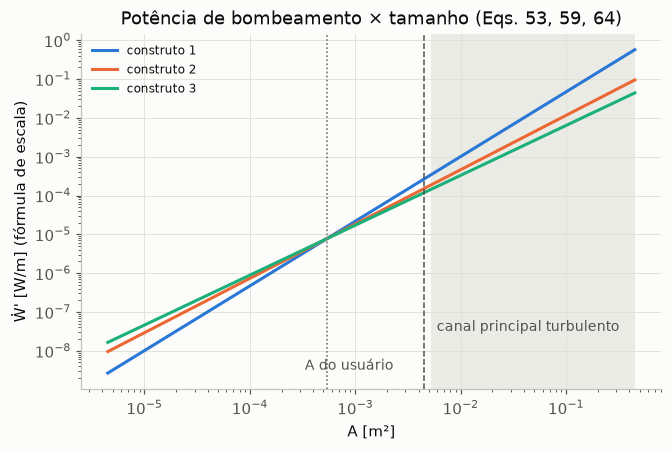

In [31]:
# --- Comparação entre ordens e escolha do melhor desenho ---
resumo = pd.DataFrame([dict(ordem=p['ordem'], viavel=p['viavel'],
                            n_por_nivel=', '.join(f"{p['ns'][i]:.3g}" for i in range(1, p['ordem'] + 1)),
                            n_inteiros=', '.join(str(max(1, int(round(p['ns'][i])))) for i in range(1, p['ordem'] + 1)),
                            dP_total_Pa=p['dP_total'], W_por_m=p['W'], W_total_W=p['W']*PROFUNDIDADE,
                            W_formula_escala=p['W_escala'], razao_soma_sobre_escala=p['W']/p['W_escala'])
                       for p in projetos])
display(resumo)
viaveis = [p for p in projetos if p['viavel']]
if viaveis:
    melhor = min(viaveis, key=lambda p: p['W'])
    print(f"Melhor desenho viável: construto de ordem {melhor['ordem']}  ->  Ẇ' = {melhor['W']:.4g} W/m "
          f"({melhor['W']*PROFUNDIDADE:.4g} W para {PROFUNDIDADE} m de profundidade)")
else:
    melhor = min(projetos, key=lambda p: p['W'])
    print(f"NENHUM desenho passou em todos os critérios. Menor Ẇ' (fora da validade): ordem {melhor['ordem']}. "
          'Revise AREA, PHI ou t1 (veja C.4).')
print(f"ΔP resultante no canal elementar = {melhor['tabela'].dP.iloc[0]:.4g} Pa "
      f"(compare com DELTA_P_ELEM = {DELTA_P_ELEM} Pa, imposto na Seção C.3)")

# --- Ẇ'(A) para cada ordem (fórmulas de escala), transições, limite laminar e área do usuário ---
A_v = np.logspace(np.log10(AREA) - 3, np.log10(AREA) + 2, 300)
fig, ax = plt.subplots(figsize=(6.8, 4.2))
for k, cor in zip(range(1, ORDEM_MAX + 1), CORES):
    ph = phis_para_ordem(k)
    ax.loglog(A_v, [C_HP*M3**2*NU*d_el**2/RHO*float(f_W[k](a/d_el**2, *ph)) for a in A_v], color=cor, label=f'construto {k}')
if PHI_TOTAL is None and ORDEM_MAX >= 2:
    for (i, j) in [(1, 2), (2, 3)][:ORDEM_MAX - 1]:
        At = d_el**2*float(sp.lambdify(list(phi[:j]), resolve_monomio(construto[i]['W'], construto[j]['W'], x))(*PHI[:j]))
        ax.axvline(At, color=MUDO, lw=1, ls=':')
ax.axvspan(A_LAM, A_v[-1], color=GRADE, alpha=0.6, lw=0)
ax.axvline(AREA, color=TINTA2, lw=1, ls='--')
ymin = ax.get_ylim()[0]
rotulo(ax, AREA, ymin*4, 'A do usuário', dx=-78); rotulo(ax, A_LAM, ymin*40, 'canal principal turbulento')
ax.set(xlabel='A [m²]', ylabel="Ẇ' [W/m] (fórmula de escala)", title="Potência de bombeamento × tamanho (Eqs. 53, 59, 64)")
ax.legend(fontsize=8, loc='upper left'); plt.show()

## C.5 Resumo final e exportação

In [32]:
final = {**{f'[prop] {k}': v for k, v in prop.items()},
         **{f'[tempo] {k}': v for k, v in res_tempo.items()},
         **{f'[elemento] {k}': v for k, v in el.items()},
         '[construto] ordem ótima': melhor['ordem'],
         "[construto] Ẇ' [W/m]": melhor['W'],
         '[construto] Ẇ total [W]': melhor['W']*PROFUNDIDADE,
         '[construto] ΔP total [Pa]': melhor['dP_total']}
df_final = pd.Series(final, name='valor').to_frame()
df_final.to_csv('resultados_adsorcao_constructal.csv')
display(df_final)
try:
    from google.colab import files
    files.download('resultados_adsorcao_constructal.csv')
except Exception:
    print('Arquivo salvo: resultados_adsorcao_constructal.csv')

,valor
[prop] C_Aga [kmol/m³],0.009076
[prop] C_Agd [kmol/m³],0.001210
[prop] K_ads [-],272.685273
[prop] K_des [-],272.685273
[prop] K0 (Eq.14) [-],0.001513
[prop] C_Asa = K_ads·C_Aga [kmol/m³],2.475000
[prop] C_A0 = K_des·C_Agd [kmol/m³],0.330000
[prop] ρ gás [kg/m³],1.840088
[prop] ν [m²/s],0.000010
[prop] D gás [m²/s],0.000011


Arquivo salvo: resultados_adsorcao_constructal.csv


---
# PARTE D: Notas

## D.1 Inconsistências encontradas no artigo (todas verificadas acima)

| Local | Impresso | Correto | Onde foi verificado |
|---|---|---|---|
| Eq. 61 | $n_{3,\mathrm{opt}}\sim\phi_1^{-9/14}\cdots$ | $\phi_1^{-6/7}\ (=\phi_1^{-12/14})$ | B.2: recursão + consistência com Eqs. 62–64 |
| Seção 8, após Eq. 67 | $\phi_2=\phi_{12}/4$ | $\phi_2=\phi_{12}/6$ | B.3: com $1/4$ a restrição 67 não fecha |
| Seção 8, após Eq. 68 | $\phi_2=(1/4)\phi_{12}=(1/5)\phi_{13}$ | sequencial: $(2/15)\phi_{13}$; global: $\phi_1=\tfrac25,\ \phi_2=\tfrac15,\ \phi_3=\tfrac1{10}$ (×$\phi_{13}$) | B.3 |
| Eq. 69 | $p=1,\ 3/5,\ 9/35$ | $p=1,\ 3/5,\ 3/7,\ \dots=3/(2i+1)$ | B.2 (tabela de expoentes) |
| Seção 5 (texto) | "Combining Eqs. (29), (35) and (36)" | Eqs. (30), (35), (36) | B.1 |
| Seção 5 (texto) | "Figs. 3 and 6 showed that for $\theta_2\ll1$, $\tau=1$" | só vale no modelo 2 (Fig. 6). No modelo 1, $\tau_{\mathrm{opt}}\approx\sqrt{2/\theta_2}\to\infty$ | A.1 (Fig. 3) |
| Eqs. 10, 11, 20, 28 | $j_A$ em kmol m⁻² s⁻¹ | como escritas: kmol m⁻³ s⁻¹; multiplique por $d_s$ para ter fluxo | A.1 |
| Nomenclatura | $d$ definido duas vezes | é a espessura da camada/canal de gás | — |
| Eq. 66 × Fig. 11 | um canal $d_1$ por 1º construto | a figura mostra dois (entrada/saída) | ajustável em `CANAIS_POR_NIVEL` |

## D.2 Hipóteses e passos que **este notebook** introduziu (fora do artigo)

1. **$U_m$ (se `U_M=None`):** aproximação LDF de Glueckauf para uma placa de espessura $d_s$ exposta de um lado,
   $k_{LDF}=3D_s/d_s^2$, então $U_m=k_{LDF}\,d_s=3D_s/d_s$. Assim $\theta=3D_st/d_s^2$ é um número de Fourier.
   Se você tiver $U_m$ medido (ou $k_{LDF}$), prefira-o: $U_m=k_{LDF}\,d_s$.
2. **$D$ do gás (se `D_GAS=None`):** correlação de Fuller–Schettler–Giddings.
3. **Henry adimensional a partir do Henry mássico:** $K=\rho_s\,H\,R\,T$ (com $H$ em kmol kg⁻¹ Pa⁻¹). Van't Hoff (Eq. 14) aplicado a $H$.
4. **$C_{A0}=K_{des}C_{Agd}$:** nos modelos 1 e 3, o sólido regenerado está em equilíbrio com o gás de dessorção.
5. **$\dot m'''=\rho/t_1$:** vazão de gás por volume, consequência de $L=Ut_1$. Usada nas Seções 6–8, mas não explicitada lá.
6. **$\Delta C$ das Eqs. 40–43:** escala do lado do gás, $C_{Aga}-C_{A0}/K_{ads}$ (máximo que o gás pode perder). Também comparamos com a capacidade do sólido.
7. **Modelo 3:** $r=d_s/d$ resolvido por ponto fixo, porque $d$ depende de $t_1$.
8. **`C_HP`:** o artigo usa $\Delta P\sim\mu LU/d^2$ (coeficiente 1). Para placas paralelas em regime laminar desenvolvido o coeficiente exato é 12.
   Ele multiplica todos os níveis igualmente, então **não altera** os $n_{i,\mathrm{opt}}$ nem a ordem ótima. Altera $L$ (Seção 5), $\Delta P$ e $\dot W'$.
9. **Viabilidade:** um construto de ordem $k$ só é aceito se $n_i\ge2$ em todos os níveis, $L_i/d_i>1$ e $Re_i<$ `RE_MAX`.
   Resultado derivado aqui: $Re_i=(A_i/d^2)/Sc$. Para gases isso limita o tamanho de cada módulo a $A\lesssim Re_{\max}Sc\,d^2$.
10. **Números inteiros:** os $n_i$ saem contínuos (como no artigo). A coluna `n_inteiros` sugere o arredondamento.
11. **`METODO_N='numerico'`:** em vez da regra "termos iguais", minimiza o $\Delta P$ total exato da geometria reconstruída.
    Os $n_i$ mudam ~10–30% e $\dot W'$ cai só alguns por cento (3–6% no exemplo). Isso mostra o tamanho das constantes $O(1)$ da análise de escala.
12. **Equipartição:** no ótimo de escala todos os níveis têm o mesmo $\Delta P$, então a soma vale $(k+1)\times$ a fórmula de um termo.

## D.3 Limitações do próprio método (Seção 9 do artigo)

* Análise de **escala**: os valores absolutos valem a menos de constantes $O(1)$. As leis de potência e as comparações são robustas (B.4).
* Adsorção e dessorção são modeladas de forma simplificada e **desacoplada** (a dessorção só entra por $\theta_2$ ou $a_0$).
* Isoterma **linear** (Henry): em pressões parciais altas, onde a isoterma curva (Langmuir etc.), $K$ passa a depender de $C$.
* Geometria **2-D** (resultados por unidade de profundidade).